
  # Laboratorio 1 - Implementando un Algoritmo Genético para Optimizar  una Parábola

  **Materia:** Inteligencia Artificial (FP-UNA)
  **Profesor:** Christian von Lücken
  **Alumno:** David Gómez

  **Objetivo:** encontrar los parámetros `(a, b, c)` de la parábola `y =
  a·x² + b·x + c`
  que produzcan la curva **más plana posible hacia arriba** (`a > 0`),
  usando un
  algoritmo genético implementado desde cero.

 ## Parte 1 - Lectura y comprensión teórica


 ### 1.1 ¿Qué es un algoritmo genético y en qué se inspira?
 

Un algoritmo genético (GA) es una **metaheurística de búsqueda y optimización, poblacional y estocástica**: resuelve un problema haciendo evolucionar un conjunto de soluciones candidatas, en lugar de construir una única solución paso a paso. Pertenece a la familia de las heurísticas tal como se las definió en clase, o sea técnicas que buscan soluciones buenas(pero que pueden no ser las mejores) a un costo computacional razonable, sin garantizar factibilidad ni optimalidad, pero no pueden dererminar qué tan cerca quedo el resultado del valor optimo. Fue desarrollado por **John H. Holland** a principios de la década de 1960 con el nombre de "planes reproductivos y adaptativos", en un intento por hacer que las computadoras aprendieran imitando el proceso de la evolución.

Su funcionamiento es un ciclo que se repite: se parte de una población inicial de soluciones codificadas, se le asigna a cada una un valor de aptitud (*fitness*) que mide su calidad, y se construye la generación siguiente aplicando selección, cruzamiento y mutación. Al repetir el ciclo, la aptitud de la población tiende a mejorar.

La inspiración es el **neo-darwinismo**, que explica toda la vida en el planeta mediante cuatro procesos: **reproducción, mutación, competencia y selección**. Un algoritmo genético es, literalmente, una simulación computacional de esos cuatro procesos. La referencia de fondo es Darwin (1858): la evolución se origina por cambios aleatorios en características hereditarias combinados con un proceso de selección natural. La distinción con Lamarck es importante y no es un detalle histórico: el individuo no mejora durante su vida para después transmitir esa mejora, sino que la variación aparece **al azar** y es la selección la que la filtra. Por eso en un GA la mutación es ciega al objetivo y toda la presión hacia la mejora la ejerce la selección.

De la biología se toma también el vocabulario: el **cromosoma** (o individuo) es una solución candidata codificada; el **gen** es cada una de sus componentes; el **alelo**, el conjunto de valores que un gen puede tomar; el **genotipo** es la solución codificada y el **fenotipo**, la solución ya decodificada en el dominio del problema. En este laboratorio el individuo es la terna `(a, b, c)` con los coeficientes de la parábola.

### 1.2 Población, función de fitness, selección, crossover y mutación

**Población.** Conjunto de soluciones candidatas que el algoritmo mantiene y hace evolucionar en paralelo. Que sean varias a la vez es lo que distingue a un GA de una búsqueda local, y lo que le permite muestrear distintas regiones del espacio al mismo tiempo.
*En este laboratorio:* `population_size` ternas `(a, b, c)` de números reales, generadas al azar con `random.uniform(lower_bound, upper_bound)` dentro del rango `[-50, 50]`. La codificación es directa en punto flotante y no binaria, así que acá el genotipo coincide con el fenotipo.

**Función de fitness (aptitud).** Asigna a cada individuo un número que mide qué tan buena es la solución que representa. Es el único componente que depende del problema: todo el resto del algoritmo es genérico.
*En este laboratorio:* mide qué tan plana es la parábola. Calcula el vértice en `x = -b/(2a)`, evalúa cuánto sube la curva desde el vértice hasta `x = -1` y hasta `x = 1`, suma esas dos subidas (`curviness`) y devuelve el valor **negado**, porque el GA maximiza y lo que se busca es minimizar la curvatura. Si `a <= 0` devuelve `-inf`, descartando de entrada las parábolas que abren hacia abajo. Nótese que `c` no influye en el resultado: desplazar la parábola verticalmente no la hace más ni menos plana.

**Selección.** Decide qué individuos se reproducen, dando más probabilidad a los de mejor aptitud. La intensidad de ese sesgo es la **presión selectiva**: mucha presión acelera la convergencia pero aumenta el riesgo de convergencia prematura; poca presión hace que el algoritmo casi no progrese.
*En este laboratorio:* selección por **torneo de tamaño 3**: se toman tres individuos al azar y pasa el de mejor fitness, repitiendo hasta completar la población. La alternativa clásica es la **ruleta**, donde la probabilidad de ser elegido es proporcional al fitness.

**Crossover (cruzamiento).** Combina el material genético de dos padres para producir hijos. Es el mecanismo de **explotación**: no crea material nuevo, recombina el que ya está presente en la población.
*En este laboratorio:* cruzamiento **aritmético**. Se sortea un `alpha` en `[0, 1)` y los hijos resultan de las combinaciones `alpha·p1 + (1-alpha)·p2` y `alpha·p2 + (1-alpha)·p1`. Cada hijo cae sobre el segmento que une a los dos padres, lo que explica por qué la población tiende a contraerse si no interviene la mutación.

**Mutación.** Altera genes al azar con cierta probabilidad. Es el mecanismo de **exploración** o diversificación: es la única fuente de material genético verdaderamente nuevo y, por lo tanto, lo único capaz de sacar a la población de una región donde quedó estancada.
*En este laboratorio:* cada gen se modifica con probabilidad `mutation_rate` sumándole un valor uniforme en `[-1, 1]`, y a continuación se lo recorta para que no se salga de `[lower_bound, upper_bound]`.

A estos cinco componentes el código del tutorial le agrega **elitismo**: el mejor individuo de cada generación se copia sin modificaciones a la generación siguiente, de manera que la mejor solución encontrada nunca se pierde.

### 1.3 ¿Por qué se usa un algoritmo genético para resolver problemas de optimización?

Existen técnicas clásicas muy eficaces cuando el problema tiene la estructura adecuada: el método Simplex para optimización lineal, el gradiente conjugado para la no lineal, la programación dinámica o *branch & bound* para construir soluciones parcialmente. Un algoritmo genético no compite con ellas en ese terreno; se recurre a él justamente cuando esas condiciones no se cumplen.

Un problema se vuelve difícil, en el sentido visto en clase, cuando el número de soluciones posibles es tan grande que una búsqueda exhaustiva resulta inviable el caso típico es el problema del viajante, donde con 50 ciudades hay del orden de 10²⁵ recorridos posibles, cuando la función de evaluación es ruidosa o varía con el tiempo, lo que obliga a trabajar con un conjunto de soluciones en lugar de una sola, o cuando las restricciones son tantas que incluso construir una solución factible es complicado.

En esas condiciones un GA aporta tres ventajas concretas:

- **No necesita derivadas** ni que la función objetivo sea continua o diferenciable. Alcanza con poder evaluarla, es decir, sirve para optimización de caja negra.
- **Trabaja con una población**, de modo que muestrea varias regiones del espacio simultáneamente. Eso lo hace menos propenso a quedar atrapado en un óptimo local que una búsqueda que avanza siguiendo una única solución.
- **Es independiente del dominio.** Lo único específico del problema son la codificación y la función de fitness; el resto (selección, cruzamiento, mutación) es idéntico para una parábola que para el problema del viajante.

La contrapartida es que un GA es una heurística: entrega soluciones buenas a un costo computacional razonable, pero no garantiza alcanzar el óptimo global ni permite saber, en general, a qué distancia del óptimo quedó. Este laboratorio lo ilustra con claridad: la curvatura se minimiza cuando `a` tiende a cero por derecha y `b` tiende a cero, es decir sobre el borde de la región factible (`a > 0`), de modo que el algoritmo puede acercarse indefinidamente pero nunca llegar exactamente.

## Parte 2 - Implementación guiada

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from prettytable import PrettyTable

random.seed(42) # misma semilla para que podamos tener los mismos resultados y evaluar el resultado

In [2]:
def create_initial_population(size, lower_bound, upper_bound):
    population = []
    for _ in range(size):
        individual = (random.uniform(lower_bound, upper_bound), 
                      random.uniform(lower_bound, upper_bound),
                      random.uniform(lower_bound, upper_bound)
                      )
        population.append(individual)
    return population

In [3]:
def fitness_function(params):
    a, b, c = params
    if a <= 0:
        return -float('inf') # penalizamos las parabolas que se abren hacia abajo

    vertexX = -b / (2 * a)
    vertexY = a * vertexX**2 + b *vertexX + c

    yLeft = a * (-1) ** 2 + b * (-1) + c # y en x = -1
    yRight = a * (1) ** 2 + b * (1) + c # y en x = 1

    curviness = abs(yLeft - vertexY) + abs(yRight - vertexY) 
    return -curviness

In [4]:
population = create_initial_population(5, -50, 50)
for ind in population:
    print(ind)

for p in [(0.5, 0, 3), (0.5, 0, -40), (2, 3, 1), (0.1, 0, 0), (5, 0, 0), (-0.5, 0, 3), (0,1, 1)]:
    print(p, "->", fitness_function(p))

(13.942679845788376, -47.498924477733304, -22.497068163088073)
(-27.678926185117724, 23.647121416401234, 17.669948742291126)
(39.217956770484534, -41.30611673705839, -7.807818031472955)
(-47.020278056192964, -28.136202519639664, 0.5355288103362383)
(-47.34640303161364, -30.11623493133515, 14.988443777952327)
(0.5, 0, 3) -> -1.0
(0.5, 0, -40) -> -1.0
(2, 3, 1) -> -6.25
(0.1, 0, 0) -> -0.2
(5, 0, 0) -> -10.0
(-0.5, 0, 3) -> -inf
(0, 1, 1) -> -inf


In [5]:
def selection(population, fitnesses, tournament_size=3):
    selected = []
    for _ in range(len(population)):
        tournament = random.sample(list(zip(population, fitnesses)), tournament_size)
        winner = max(tournament, key=lambda x: x[1] )[0]
        selected.append(winner)
    return selected


In [6]:
selectioned = selection(population, [fitness_function(p) for p in population])
for ind in selectioned:
    print(ind, "->", fitness_function(ind))

(13.942679845788376, -47.498924477733304, -22.497068163088073) -> -108.79332901653116
(39.217956770484534, -41.30611673705839, -7.807818031472955) -> -100.18864392772366
(-27.678926185117724, 23.647121416401234, 17.669948742291126) -> -inf
(39.217956770484534, -41.30611673705839, -7.807818031472955) -> -100.18864392772366
(39.217956770484534, -41.30611673705839, -7.807818031472955) -> -100.18864392772366


In [7]:
def crossover(parent1, parent2): # el cruzamiento
    alpha = random.random()
    child1 = tuple(alpha * p1 + (1 - alpha) * p2 for p1, p2 in zip(parent1, parent2))
    child2 = tuple(alpha * p2 + (1 - alpha) * p1 for p1, p2 in zip(parent1, parent2))
    return child1, child2

def mutation(individual, mutation_rate, lower_bound, upper_bound):
    individual = list(individual)
    for i in range(len(individual)):
        if random.random() < mutation_rate:
            mutation_amount = random.uniform(-1, 1)
            individual[i] += mutation_amount
            individual[i] = max(min(individual[i], upper_bound), lower_bound)
    return tuple(individual)


In [8]:
for parent1, parent2 in zip(selectioned[::2], selectioned[1::2]):
    child1, child2 = crossover(parent1, parent2)
    print("Parents:", parent1, parent2)
    print("Children:", child1, child2)
    print("mutated Children:", mutation(child1, 0.1, -50, 50), mutation(child2, 0.1, -50, 50))
    print()

Parents: (13.942679845788376, -47.498924477733304, -22.497068163088073) (39.217956770484534, -41.30611673705839, -7.807818031472955)
Children: (29.61518903562354, -43.65893346533902, -13.38866518236414) (23.54544758064937, -45.146107749452675, -16.91622101219689)
mutated Children: (29.61518903562354, -43.65893346533902, -13.38866518236414) (23.464297339993056, -45.146107749452675, -16.91622101219689)

Parents: (-27.678926185117724, 23.647121416401234, 17.669948742291126) (39.217956770484534, -41.30611673705839, -7.807818031472955)
Children: (33.946469142751646, -36.187788704728504, -5.800164963103585) (-22.407438557384836, 18.52879338407135, 15.662295673921758)
mutated Children: (33.946469142751646, -36.187788704728504, -5.800164963103585) (-22.407438557384836, 18.52879338407135, 15.984822311057178)



In [9]:
def genetic_algorithm(population_size, lower_bound, upper_bound, generations, mutation_rate):
    population = create_initial_population(population_size, lower_bound, upper_bound)
    
    best_performers = [] # mejor individio por cada gneracion
    all_populations = [] # snapshot de todas las generaciones

    table = PrettyTable()
    table.field_names = ["Generation", "a", "b", "c", "Fitness"]

    for generation in range(generations):
        fitnesses = [fitness_function(ind) for ind in population]

        best_individual = max(population, key=fitness_function)
        best_fitness = fitness_function(best_individual)
        best_performers.append((best_individual, best_fitness))
        all_populations.append(population[:])
        table.add_row([generation + 1, best_individual[0], best_individual[1], best_individual[2], best_fitness])

        population = selection(population, fitnesses)

        next_population = []
        for i in range(0, len(population), 2):
            child1, child2 = crossover(population[i], population[i + 1])
            next_population.append(mutation(child1, mutation_rate, lower_bound, upper_bound))
            next_population.append(mutation(child2, mutation_rate, lower_bound, upper_bound))

        next_population[0] = best_individual
        population = next_population

    print(table)
    return max(population, key=fitness_function), best_performers, all_populations


In [10]:
population_size = 100
lower_bound = -50
upper_bound = 50
generations = 20
mutation_rate = 1

random.seed(42)
best_solution, best_performers, all_populations = genetic_algorithm(
    population_size, lower_bound, upper_bound, generations, mutation_rate
)

print(f"\nMejor solución: a = {best_solution[0]}, b = {best_solution[1]}, c = {best_solution[2]}")


+------------+---------------------+-----------------------+--------------------+----------------------+
| Generation |          a          |           b           |         c          |       Fitness        |
+------------+---------------------+-----------------------+--------------------+----------------------+
|     1      |  7.1043093325284445 |  -2.7328973688205878  | 28.461942429075336 |  -14.73426638666647  |
|     2      |  7.1043093325284445 |  -2.7328973688205878  | 28.461942429075336 |  -14.73426638666647  |
|     3      |  4.872578589027569  |  -4.6020073034288025  | 3.1526782780483504 | -11.918387515324945  |
|     4      |  4.872578589027569  |  -4.6020073034288025  | 3.1526782780483504 | -11.918387515324945  |
|     5      |  4.872578589027569  |  -4.6020073034288025  | 3.1526782780483504 | -11.918387515324945  |
|     6      |  4.474998141528115  |  -4.9923390990109295  | 2.9343608928326255 |  -11.7347404205144   |
|     7      |  4.129848073535627  |   -3.6066400416307

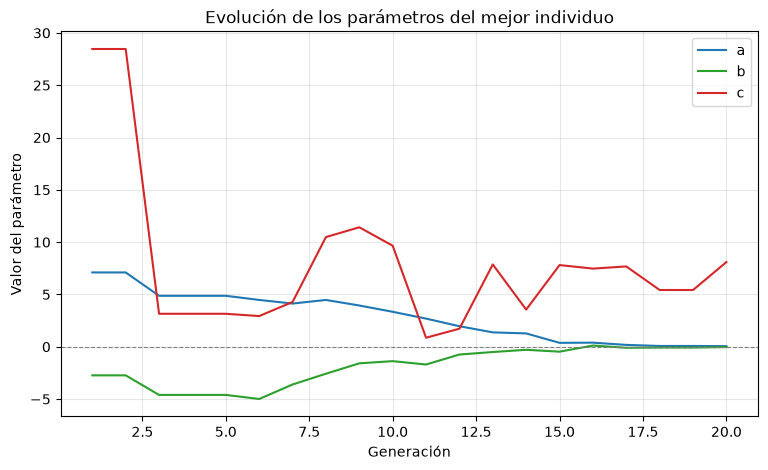

In [11]:
generations_list = list(range(1, len(best_performers) + 1))
a_values = [ind[0][0] for ind in best_performers ]
b_values = [ind[0][1] for ind in best_performers ]
c_values = [ind[0][2] for ind in best_performers ]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(generations_list, a_values, label='a', color='tab:blue')
ax.plot(generations_list, b_values, label='b', color='tab:green')
ax.plot(generations_list, c_values, label='c', color='tab:red')
ax.axhline(0, color='gray', lw=0.8, ls='--')
ax.set_xlabel('Generación')
ax.set_ylabel('Valor del parámetro')
ax.set_title('Evolución de los parámetros del mejor individuo')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

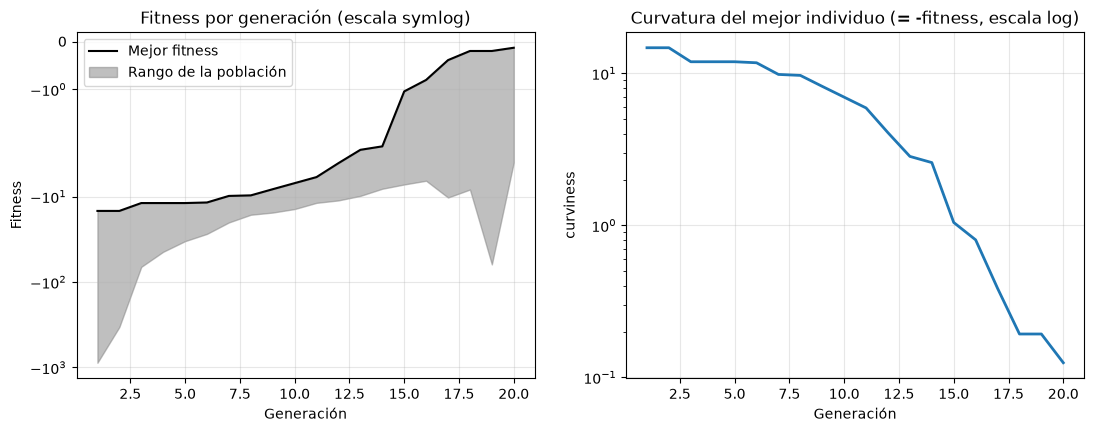

In [12]:
best_fitness_values = [fit[1] for fit in best_performers]

min_fitness_values, max_fitness_values = [], []
for pop in all_populations:
    finites = [f for f in map(fitness_function, pop) if f != -float('inf')]
    min_fitness_values.append(min(finites) if finites else float('nan'))
    max_fitness_values.append(max(finites) if finites else float('nan'))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].plot(generations_list, best_fitness_values, label='Mejor fitness', color='black')
axs[0].fill_between(generations_list, min_fitness_values, max_fitness_values,
                    color='gray', alpha=0.5, label='Rango de la población')
axs[0].set_yscale('symlog')
axs[0].set_xlabel('Generación'); axs[0].set_ylabel('Fitness')
axs[0].set_title('Fitness por generación (escala symlog)')
axs[0].legend(); axs[0].grid(alpha=0.3)

axs[1].semilogy(generations_list, [-f for f in best_fitness_values], color='tab:blue', lw=2)
axs[1].set_xlabel('Generación'); axs[1].set_ylabel('curviness')
axs[1].set_title('Curvatura del mejor individuo (= -fitness, escala log)')
axs[1].grid(alpha=0.3)

plt.show()


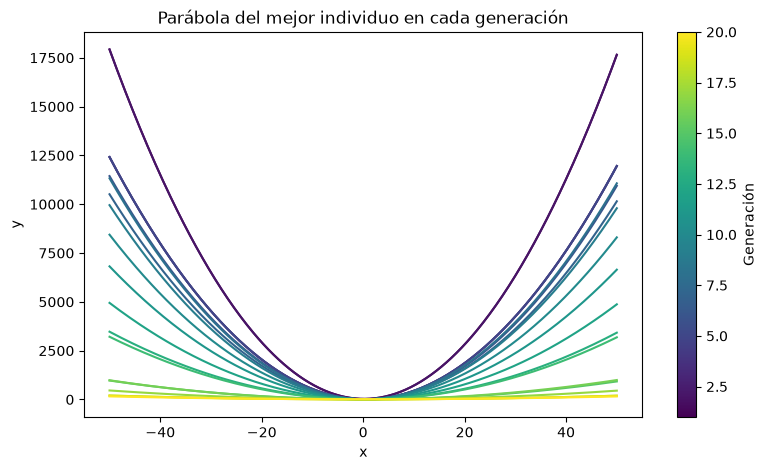

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = plt.cm.viridis(np.linspace(0, 1, len(best_performers)))
x_range = np.linspace(lower_bound, upper_bound, 400)

for i, (best_ind, best_fit) in enumerate(best_performers):
    a, b, c = best_ind
    ax.plot(x_range, a * x_range**2 + b * x_range + c, color=colors[i])

sm = plt.cm.ScalarMappable(cmap='viridis',
                            norm=plt.Normalize(1, len(best_performers)))
sm.set_array([])
fig.colorbar(sm, ax=ax, label='Generación')
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('Parábola del mejor individuo en cada generación')
plt.show()

### Pregunta de reflexión

> **¿Qué significa que el algoritmo "encuentre" valores de a ≈ 0 (pero positivo), b ≈ 0 y c cualquiera? ¿Por qué penaliza a ≤ 0 en la función de fitness?**

Las tres observaciones se explican con un único hecho algebraico. La función de fitness evalúa la parábola en el vértice y en `x = ±1`, y suma las dos diferencias en valor absoluto. Al desarrollar esas restas, la expresión se simplifica por completo:

```
vértice:        y_v = c - b²/(4a)

y(-1) - y_v  =  a - b + b²/(4a)  =  (2a - b)² / (4a)
y(+1) - y_v  =  a + b + b²/(4a)  =  (2a + b)² / (4a)

curviness    =  [(2a - b)² + (2a + b)²] / (4a)  =  (8a² + 2b²) / (4a)
```

es decir:

```
curviness = 2·|a| + b²/(2·|a|)            fitness = -curviness
```

Toda la respuesta está contenida en esa expresión.

#### a ≈ 0 pero positivo

Con `b = 0` la curvatura se reduce a `2a`, que decrece de forma monótona a medida que `a` se achica. **No existe un mínimo**: el ínfimo es 0 y no se alcanza, porque `a = 0` está excluido del dominio. Que el algoritmo "encuentre" `a ≈ 0` positivo significa, entonces, que convergió al **borde de la región factible**, y que el óptimo es un límite antes que un punto alcanzable. Geométricamente se le está pidiendo aproximar una parábola degenerada: la curva más plana que abre hacia arriba es, en el límite, una recta horizontal.

Esto tiene una consecuencia práctica comprobable: el algoritmo nunca termina de converger. Repitiendo la misma corrida con más generaciones, `a` sigue bajando indefinidamente (ver la celda siguiente).

#### b ≈ 0

El término `b²/(2·|a|)` penaliza que el vértice esté desplazado respecto de `x = 0`. Con `b ≠ 0` el vértice se ubica en `x = -b/(2a)` y la parábola sube más de un lado que del otro dentro del intervalo `[-1, 1]`, que es justamente donde se mide la planitud.

Dos detalles de ese término importan. `b` entra al cuadrado, así que el castigo es simétrico respecto de su signo; y está **dividido por `a`**, de modo que se vuelve más severo a medida que `a` se achica. La presión selectiva sobre `b` se intensifica sola a lo largo de la corrida. Los resultados lo confirman: a las 50 generaciones el término de `a` aporta el 91 % de la curvatura y el de `b` apenas el 9 %, mientras que a las 200 generaciones la proporción se invierte y `b` pasa a aportar el 64 %. Seguir achicando `a` deja de rendir si `b` no lo acompaña.

#### c cualquiera

`c` no aparece en la expresión: se cancela al restar. No es una casualidad algebraica sino el reflejo de un hecho geométrico: `c` desplaza la parábola entera verticalmente, vértice incluido, y la planitud es una propiedad de la **forma** de la curva, no de su posición.

En términos del algoritmo, el paisaje de fitness es perfectamente **plano** a lo largo del eje `c`, de modo que la selección no ejerce ninguna presión en esa dirección. `c` es un **gen neutro**: su valor final no es producto de la optimización sino del arrastre aleatorio del cruzamiento y la mutación. Cualquier valor de `c` es igualmente óptimo, y eso es exactamente lo que muestra la gráfica de las parábolas: las curvas de las últimas generaciones son todas igual de planas, pero están a distintas alturas.

#### Por qué se penaliza a ≤ 0

Hay dos razones, de naturaleza distinta.

**La primera es de definición.** Con `a = 0` la expresión `x_v = -b/(2a)` divide por cero, y además la función deja de ser una parábola: es una recta. Por eso la guarda es `a <= 0` y no `a < 0`.

**La segunda** Como la función toma valores absolutos, el resultado depende de `|a|` y no de `a`. Una parábola con `a = -0.001` obtiene **exactamente el mismo fitness** que una con `a = +0.001`. Sin la penalización, el algoritmo sería por completo indiferente entre una curva que abre hacia arriba y su reflejo que abre hacia abajo, y aproximadamente la mitad de las soluciones finales quedarían invertidas, lo que no cumple con lo que se dice en el enunciado que la parabola sea plana **hacia arriba**.

La penalización no es una formalidad ni el manejo de un caso de borde: es el único mecanismo que rompe esa simetría y convierte "la parábola más plana" en "la parábola más plana que abre hacia arriba". La forma concreta de implementarla devolver `-inf` es discutible y se retoma en la Parte 4.

#### Evidencia en los resultados obtenidos

| Afirmación | Evidencia en esta corrida |
|---|---|
| `a → 0⁺` | 7.1043 en la generación 1, 0.0592 en la 20 |
| `b → 0` | -2.7329 en la generación 1, -0.0276 en la 20 |
| `c` no converge | 28.46 → 3.15 → 11.42 → 0.87 → 7.87 → 8.10, sin dirección |
| `c` es libre, no indefinido | las curvas finales de la tercera gráfica son planas pero están a distinta altura |
| el óptimo nunca se alcanza | celda siguiente: 20, 50 y 200 generaciones |

In [14]:
# ¿El algoritmo converge a un punto, o se acerca indefinidamente al borde a = 0?
import io, contextlib

for n_gen in (20, 50, 200):
    random.seed(42)
    with contextlib.redirect_stdout(io.StringIO()):      # silencia la tabla de PrettyTable
        _, bp, _ = genetic_algorithm(population_size, lower_bound, upper_bound,
                                     n_gen, mutation_rate)
    ind, fit = bp[-1]
    aporte_a = 2 * abs(ind[0])
    aporte_b = ind[1] ** 2 / (2 * abs(ind[0]))
    total = aporte_a + aporte_b
    print(f"{n_gen:>4} gen -> a = {ind[0]:.8f}   b = {ind[1]:>12.8f}   fitness = {fit:.8f}"
          f"   | curvatura: {aporte_a/total:>4.0%} por a, {aporte_b/total:>4.0%} por b")

  20 gen -> a = 0.05917645   b =  -0.02758193   fitness = -0.12478083   | curvatura:  95% por a,   5% por b
  50 gen -> a = 0.01611702   b =  -0.01017562   fitness = -0.03544627   | curvatura:  91% por a,   9% por b
 200 gen -> a = 0.00623640   b =  -0.01652514   fitness = -0.03436686   | curvatura:  36% por a,  64% por b


---
## Parte 3 - Experimentación y análisis

**Nota metodológica.** Un algoritmo genético es estocástico: la población inicial y los sorteos de
selección, cruzamiento y mutación cambian en cada corrida. Comparar configuraciones con **una sola
ejecución** por configuración no permite distinguir el efecto del parámetro del efecto del azar.
Por eso cada configuración se ejecuta con **10 semillas distintas** (`SEEDS = 1..10`) y se reportan
media, mediana, mejor, peor y desvío estándar.

Salvo lo que cada experimento modifique, la configuración base es la del tutorial:
`population_size = 100`, `lower_bound = -50`, `upper_bound = 50`, `generations = 20`,
`mutation_rate = 1`.

In [15]:
import io, contextlib, statistics

SEEDS = tuple(range(1, 11))     # 10 corridas por configuración


def correr_experimento(**overrides):
    """Corre el GA con varias semillas. Devuelve (curvas_de_fitness, fitness_finales)."""
    params = dict(population_size=100, lower_bound=-50, upper_bound=50,
                  generations=20, mutation_rate=1)
    params.update(overrides)                 # los overrides pisan solo lo que reciben

    curvas = []
    for s in SEEDS:
        random.seed(s)
        with contextlib.redirect_stdout(io.StringIO()):     # silencia la tabla
            _, bp, _ = genetic_algorithm(**params)
        curvas.append([fit for _, fit in bp])
    return curvas, [c[-1] for c in curvas]


def graficar_experimento(resultados, titulo, etiqueta):
    """resultados: lista de (valor_del_parametro, curvas). Grafica la media y la banda min-max."""
    _, ax = plt.subplots(figsize=(9, 5))
    colores = plt.cm.viridis(np.linspace(0, 0.85, len(resultados)))
    for (valor, curvas), color in zip(resultados, colores):
        m = np.array(curvas) * -1                           # curvatura = -fitness (siempre > 0)
        gens = range(1, m.shape[1] + 1)
        ax.plot(gens, m.mean(axis=0), color=color, lw=2, label=f"{etiqueta} = {valor}")
        ax.fill_between(gens, m.min(axis=0), m.max(axis=0), color=color, alpha=0.15)
    ax.set_yscale('log')
    ax.set_xlabel('Generación')
    ax.set_ylabel('Curvatura (= -fitness, escala log)')
    ax.set_title(titulo)
    ax.legend(); ax.grid(alpha=0.3)
    plt.show()

### Experimento 1 - Tamaño de la población

+-----------------+---------------+----------+----------+-----------+---------+--------------+
| population_size | fitness medio | mediana  |  mejor   |    peor   |   desv  | evaluaciones |
+-----------------+---------------+----------+----------+-----------+---------+--------------+
|        50       |    -1.90154   | -0.20756 | -0.02626 | -11.23215 | 3.64030 |     1000     |
|       100       |    -0.15056   | -0.14805 | -0.10423 |  -0.20134 | 0.03542 |     2000     |
|       200       |    -0.07092   | -0.07571 | -0.00846 |  -0.13055 | 0.03434 |     4000     |
+-----------------+---------------+----------+----------+-----------+---------+--------------+


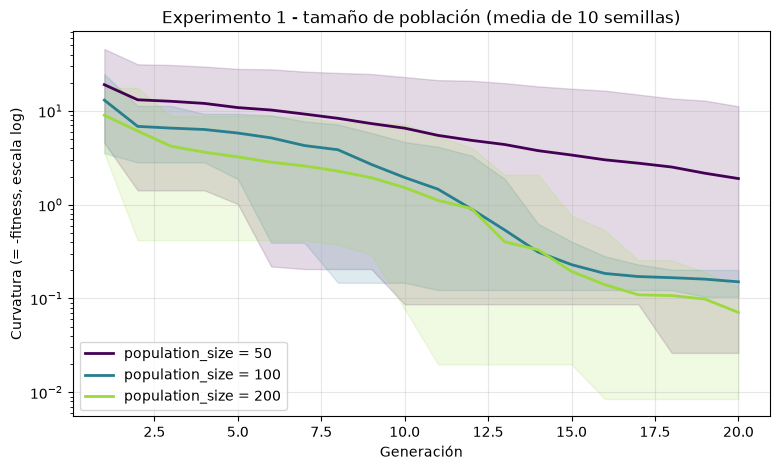

In [16]:
tabla = PrettyTable()
tabla.field_names = ["population_size", "fitness medio", "mediana", "mejor", "peor", "desv", "evaluaciones"]

resultados_1 = []
for n in (50, 100, 200):
    curvas, finales = correr_experimento(population_size=n)
    resultados_1.append((n, curvas))
    tabla.add_row([n,
                   f"{statistics.mean(finales):.5f}",
                   f"{statistics.median(finales):.5f}",
                   f"{max(finales):.5f}",
                   f"{min(finales):.5f}",
                   f"{statistics.pstdev(finales):.5f}",
                   n * 20])
print(tabla)

graficar_experimento(resultados_1,
                     "Experimento 1 - tamaño de población (media de 10 semillas)",
                     "population_size")

#### Control: igualando el presupuesto computacional

La comparación anterior no es justa. Con 200 individuos el algoritmo realiza 4000 evaluaciones de
fitness y con 50 solo 1000: es cuatro veces más cómputo. La comparación correcta mantiene fijo el
**presupuesto** (`population_size × generations = 4000`) y reparte ese presupuesto de distintas maneras.

In [17]:
tabla = PrettyTable()
tabla.field_names = ["population_size", "generations", "evaluaciones", "fitness medio", "mediana", "desv"]
for n, g in ((50, 80), (100, 40), (200, 20), (400, 10)):
    _, finales = correr_experimento(population_size=n, generations=g)
    tabla.add_row([n, g, n * g,
                   f"{statistics.mean(finales):.5f}",
                   f"{statistics.median(finales):.5f}",
                   f"{statistics.pstdev(finales):.5f}"])
print(tabla)

+-----------------+-------------+--------------+---------------+----------+---------+
| population_size | generations | evaluaciones | fitness medio | mediana  |   desv  |
+-----------------+-------------+--------------+---------------+----------+---------+
|        50       |      80     |     4000     |    -0.04651   | -0.05138 | 0.01619 |
|       100       |      40     |     4000     |    -0.05349   | -0.05835 | 0.02490 |
|       200       |      20     |     4000     |    -0.07092   | -0.07571 | 0.03434 |
|       400       |      10     |     4000     |    -1.38926   | -0.79584 | 1.41398 |
+-----------------+-------------+--------------+---------------+----------+---------+


**Análisis del Experimento 1**

Con 20 generaciones fijas, aumentar la población mejora de forma clara tanto la velocidad de
convergencia como la calidad final: el fitness medio pasa de **-1.90** con 50 individuos a **-0.15**
con 100 y **-0.07** con 200. Sin embargo, el efecto más marcado no está en la media sino en la
**dispersión**. Con 50 individuos el desvío es 3.64 y la peor de las diez corridas termina en -11.23;
con 200 el desvío cae a 0.034 y ninguna corrida se despega del resto. La brecha entre la media
(-1.90) y la mediana (-0.21) en el caso de 50 individuos lo confirma: una única corrida catastrófica
arrastra el promedio. Una población chica no es sistemáticamente mala, es **impredecible**: a veces
la población inicial contiene buen material genético y el algoritmo converge bien, y a veces no, y
entonces el cruzamiento no tiene de dónde sacarlo.

La comparación a generaciones fijas, no obstante, es engañosa, porque el costo computacional no es el
mismo. Igualando el presupuesto en 4000 evaluaciones, el orden **se invierte levemente**: -0.047 con
50×80 frente a -0.071 con 200×20, aunque la diferencia es pequeña frente al ruido y no conviene
sobreinterpretarla. El resultado contundente es el caso extremo: con 400 individuos y solo 10
generaciones el fitness medio se desploma a **-1.39**, con un desvío de 1.41. Existe un mínimo de
generaciones por debajo del cual el algoritmo no funciona, por grande que sea la población, porque
acercarse a `a → 0⁺` exige iteraciones sucesivas del "trinquete" de mutación más elitismo, y no más
muestras iniciales. En conclusión, lo que compra el tamaño de la población es **confiabilidad**, no
calidad final por unidad de cómputo.

### Experimento 2 - Tasa de mutación

+---------------+---------------+----------+----------+-----------+---------+
| mutation_rate | fitness medio | mediana  |  mejor   |    peor   |   desv  |
+---------------+---------------+----------+----------+-----------+---------+
|      0.0      |    -7.42169   | -6.75938 | -3.05427 | -12.48632 | 2.94982 |
|      0.1      |    -1.75365   | -1.09730 | -0.14239 |  -7.74245 | 2.17919 |
|      0.5      |    -0.32029   | -0.18149 | -0.06162 |  -1.65282 | 0.45092 |
|      0.8      |    -0.13083   | -0.12651 | -0.03309 |  -0.28805 | 0.07093 |
|      1.0      |    -0.15056   | -0.14805 | -0.10423 |  -0.20134 | 0.03542 |
+---------------+---------------+----------+----------+-----------+---------+


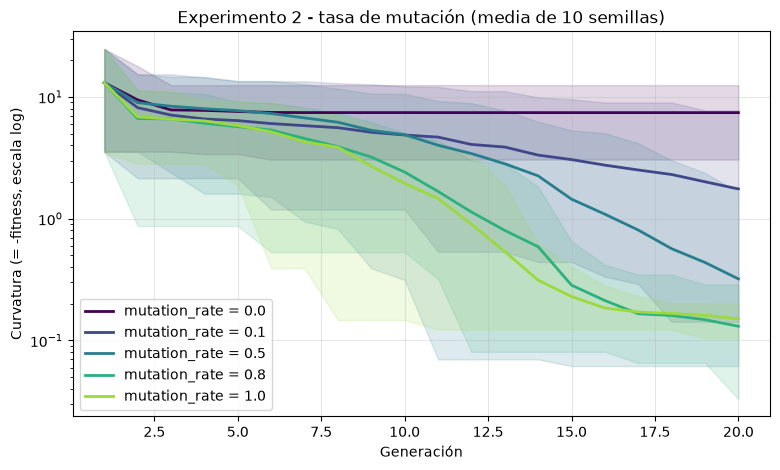

In [18]:
tabla = PrettyTable()
tabla.field_names = ["mutation_rate", "fitness medio", "mediana", "mejor", "peor", "desv"]

resultados_2 = []
for r in (0.0, 0.1, 0.5, 0.8, 1.0):
    curvas, finales = correr_experimento(mutation_rate=r)
    resultados_2.append((r, curvas))
    tabla.add_row([r,
                   f"{statistics.mean(finales):.5f}",
                   f"{statistics.median(finales):.5f}",
                   f"{max(finales):.5f}",
                   f"{min(finales):.5f}",
                   f"{statistics.pstdev(finales):.5f}"])
print(tabla)

graficar_experimento(resultados_2,
                     "Experimento 2 - tasa de mutación (media de 10 semillas)",
                     "mutation_rate")

#### Control: ¿es la tasa, o el tamaño del paso?

El resultado anterior, que más mutación sea mejor, contradice la intuición habitual. La hipótesis es
que no depende de la *tasa* sino del producto de la tasa por la **magnitud del paso**: la mutación de
este código suma `uniform(-1, 1)` sobre un dominio de ancho 100, apenas un 1 % del rango.

Para comprobarlo se repite el barrido de tasas variando el tamaño del paso.

In [19]:
def mutation_con_paso(individual, mutation_rate, lower_bound, upper_bound, paso):
    """Igual que mutation(), pero con el tamaño del paso parametrizado."""
    individual = list(individual)
    for i in range(len(individual)):
        if random.random() < mutation_rate:
            individual[i] += random.uniform(-paso, paso)
            individual[i] = max(min(individual[i], upper_bound), lower_bound)
    return tuple(individual)


def ga_con_paso(mutation_rate, paso, seed, population_size=100, generations=20,
                lower_bound=-50, upper_bound=50):
    random.seed(seed)
    population = create_initial_population(population_size, lower_bound, upper_bound)
    for _ in range(generations):
        fitnesses = [fitness_function(ind) for ind in population]
        best_individual = max(population, key=fitness_function)
        population = selection(population, fitnesses)
        next_population = []
        for i in range(0, len(population), 2):
            c1, c2 = crossover(population[i], population[i + 1])
            next_population.append(mutation_con_paso(c1, mutation_rate, lower_bound, upper_bound, paso))
            next_population.append(mutation_con_paso(c2, mutation_rate, lower_bound, upper_bound, paso))
        next_population[0] = best_individual
        population = next_population
    return max(fitness_function(ind) for ind in population)


tabla = PrettyTable()
tabla.field_names = ["paso de mutación", "rate = 0.1", "rate = 0.5", "rate = 0.8", "rate = 1.0"]
for paso, etiqueta in ((1, "±1   (1 % del rango)"), (5, "±5   (5 %)"),
                       (25, "±25  (25 %)"), (50, "±50  (50 %)")):
    fila = [etiqueta]
    for r in (0.1, 0.5, 0.8, 1.0):
        valores = [ga_con_paso(r, paso, s) for s in SEEDS]
        fila.append(f"{statistics.mean(valores):.3f}")
    tabla.add_row(fila)
print(tabla)

+----------------------+------------+------------+------------+------------+
|   paso de mutación   | rate = 0.1 | rate = 0.5 | rate = 0.8 | rate = 1.0 |
+----------------------+------------+------------+------------+------------+
| ±1   (1 % del rango) |   -1.625   |   -0.299   |   -0.120   |   -0.134   |
|      ±5   (5 %)      |   -0.437   |   -0.402   |   -0.345   |   -0.365   |
|     ±25  (25 %)      |   -1.453   |   -1.275   |   -2.050   |   -2.090   |
|     ±50  (50 %)      |   -1.841   |   -2.274   |   -2.487   |   -2.721   |
+----------------------+------------+------------+------------+------------+


**Análisis del Experimento 2**

La tasa de mutación resultó el parámetro más determinante de los dos. Con `mutation_rate = 0.0` el
algoritmo queda completamente estancado en **-7.42**, y en la gráfica se ve como una línea horizontal
desde las primeras generaciones. La causa es estructural: el cruzamiento aritmético produce
combinaciones convexas de los padres, de modo que todo hijo cae sobre el segmento que los une y
**nunca puede generar un valor de `a` menor que el más chico presente en la población**. Sin
mutación, el algoritmo no tiene forma de alcanzar el óptimo, que está en el borde `a → 0⁺`. A partir
de ahí el resultado mejora de forma monótona: -1.75 con 0.1, -0.32 con 0.5 y **-0.13 con 0.8**, para
estabilizarse en -0.15 con 1.0.

Lo interesante es que **la "demasiada aleatoriedad" que cabría esperar en el extremo alto no
aparece**. La razón es el tamaño del paso: la mutación suma un valor uniforme en [-1, 1] sobre un
dominio de ancho 100, es decir un 1 % del rango. Aun mutando los tres genes en todas las
generaciones, la perturbación es suave: en esta implementación la mutación no cumple el papel de
diversificación sino el de **búsqueda local**, un paso chico que va empujando `a` hacia el borde
`a → 0⁺` generación tras generación. Como el óptimo está justamente en ese borde y debe alcanzarse
de forma asintótica, cuanto más seguido se dé ese paso, mejor.

El experimento de control lo confirma: el parámetro relevante no es la tasa sola, sino el producto de
la tasa por la **magnitud del paso**. Con paso ±1 el mejor resultado se obtiene con tasa alta (-0.120
con 0.8); con paso ±50, medio dominio, **el efecto se invierte** y el mejor resultado pasa a obtenerse
con tasa baja (-1.841 con 0.1 frente a -2.721 con 1.0). Con un paso de esa magnitud la mutación
prácticamente re-sortea el gen y el hijo pierde lo que heredó, de modo que el algoritmo degenera
hacia búsqueda aleatoria. El elitismo evita el colapso total, pero no alcanza para compensarlo.

La convergencia prematura sí aparece, pero en el **extremo bajo**: con 0.1 la peor corrida termina en
-7.74 y el desvío es 2.18. El patrón se confirma en la dispersión, que se mueve en sentido contrario
al esperado: **más mutación produce resultados más consistentes** (desvío 0.035 con 1.0 frente a
2.18 con 0.1). Con poca mutación el resultado depende de si la población inicial tuvo suerte; con
mucha, el algoritmo explora lo suficiente como para llegar a un resultado parecido en todas las
corridas.

### Experimento 3 - Operador de selección: ruleta vs. torneo

El tercer experimento cambia el operador de selección. La implementación de referencia usa
**torneo**: sortea tres individuos y se queda con el mejor. La alternativa clásica es la **ruleta**
(*fitness-proportionate selection*), donde cada individuo recibe una porción de probabilidad
proporcional a su fitness, como un gajo de una ruleta de casino.

La fórmula de la ruleta, `p = fitness / suma_de_fitness`, asume fitness no negativo, y el de este
problema vive en `(-inf, 0]`. Trasladarla sin adaptarla rompe de tres maneras distintas:

1. **El signo la invierte, en silencio.** Con `fitnesses = [-1, -10]` la suma es `-11` y los
   cocientes dan `[0.09, 0.91]`: suman 1 y parecen probabilidades legítimas, pero el **peor**
   individuo se lleva el 91 % de las chances. No se lanza ninguna excepción; el algoritmo
   simplemente evoluciona hacia atrás.
2. **El `-inf` de la penalización envenena la suma.** Los individuos con `a <= 0` valen `-inf`, la
   suma entera se vuelve `-inf`, y los cocientes degeneran en `-0.0` para los finitos y `nan` para
   los infinitos. En la primera generación, con los límites `[-50, 50]`, aproximadamente la mitad de
   la población está en ese caso.
3. **La ruleta depende de la escala del fitness; el torneo solo del orden.** El torneo hace
   `max()` sobre tres sorteados: le importa quién le gana a quién, no por cuánto. Esta es la
   diferencia de fondo entre los dos operadores, y es lo que el experimento termina midiendo.

Las dos primeras se resuelven transformando el fitness en un peso no negativo y creciente. Se usa
`peso = 1 / (1 - f)`: como el fitness es siempre `<= 0`, el denominador vale 1 o más y el peso cae
en `(0, 1]`. El caso límite se resuelve solo, porque en Python `1 / (1 - (-inf))` da exactamente
`0.0`, que es justo la semántica buscada para la penalización: probabilidad cero, sin casos
especiales.

| fitness `f` | `1 - f` | `peso` |
|---|---|---|
| `0` (plana, inalcanzable) | `1` | `1.0` |
| `-0.2` (casi plana) | `1.2` | `0.833` |
| `-4` (curvada) | `5` | `0.200` |
| `-inf` (`a <= 0`, penalizada) | `inf` | `0.0` |

La alternativa habitual en la literatura es el *windowing* (`peso = f - min(f) + eps`), que acá no
sirve tal cual: `min()` sobre una lista que contiene `-inf` devuelve `-inf` y deja todos los pesos
en `inf`.

In [20]:
def selection_roulette(population, fitnesses):
    """Selección proporcional al fitness (ruleta).
    Devuelve una lista de len(population) individuos, con repetición.
    Misma firma que selection(), así los dos operadores son intercambiables."""
    # f <= 0  =>  1 - f >= 1  =>  peso en (0, 1]
    # f = -inf  =>  1 - f = inf  =>  peso = 0.0 exacto (las parábolas con a <= 0 nunca se eligen)
    weights = [1 / (1 - f) for f in fitnesses]

    if sum(weights) == 0:                    # caso degenerado: toda la población con a <= 0
        return random.choices(population, k=len(population))

    # random.choices (PLURAL) sortea k elementos CON reposición y acepta weights.
    # random.choice (singular) devuelve uno solo y no acepta weights: no sirve acá.
    return random.choices(population, weights=weights, k=len(population))

In [21]:
from collections import Counter

# Verificación del operador: tres individuos con pesos conocidos de antemano.
pob = [(2.0, 0.0, 0.0),      # parábola curvada:    fitness -4.0   -> peso 1/5   = 0.2000
       (0.1, 0.0, 0.0),      # casi plana:          fitness -0.2   -> peso 1/1.2 = 0.8333
       (-1.0, 0.0, 0.0)]     # se abre hacia abajo: fitness -inf   -> peso 0
fits = [fitness_function(p) for p in pob]

print("fitness:", fits)
print("pesos:  ", [1 / (1 - f) for f in fits])

random.seed(0)
conteo = Counter(selection_roulette(pob, fits)[0] for _ in range(10000))
print("conteo: ", conteo)

assert conteo[(-1.0, 0.0, 0.0)] == 0,                     "la penalización a <= 0 no llega con peso 0"
assert conteo[(0.1, 0.0, 0.0)] > conteo[(2.0, 0.0, 0.0)], "la ruleta está INVERTIDA"
assert 7700 < conteo[(0.1, 0.0, 0.0)] < 8400,             "las proporciones no se corresponden con los pesos"
print("OK: reparte 80.6 % / 19.4 % / 0 %, que es lo que dictan los pesos")

fitness: [-4.0, -0.2, -inf]
pesos:   [0.2, 0.8333333333333334, 0.0]
conteo:  Counter({(0.1, 0.0, 0.0): 8062, (2.0, 0.0, 0.0): 1938})
OK: reparte 80.6 % / 19.4 % / 0 %, que es lo que dictan los pesos


In [22]:
def genetic_algorithm_op(population_size, lower_bound, upper_bound, generations, mutation_rate,
                         selection_fn=selection, crossover_fn=crossover):
    """Copia de genetic_algorithm con el operador de selección como parámetro"""
    population = create_initial_population(population_size, lower_bound, upper_bound)

    best_performers = []
    all_populations = []

    for _ in range(generations):
        fitnesses = [fitness_function(ind) for ind in population]

        best_individual = max(population, key=fitness_function)
        best_performers.append((best_individual, fitness_function(best_individual)))
        all_populations.append(population[:])

        population = selection_fn(population, fitnesses)
        next_population = []
        for i in range(0, len(population), 2):
            child1, child2 = crossover_fn(population[i], population[i + 1])   # <<<< operador intercambiable
            next_population.append(mutation(child1, mutation_rate, lower_bound, upper_bound))
            next_population.append(mutation(child2, mutation_rate, lower_bound, upper_bound))

        next_population[0] = best_individual
        population = next_population

    return max(population, key=fitness_function), best_performers, all_populations


def genetic_algorithm_roulette(population_size, lower_bound, upper_bound, generations, mutation_rate):
    """El GA del enunciado seleccionando por ruleta. Misma firma que genetic_algorith"""
    return genetic_algorithm_op(population_size, lower_bound, upper_bound, generations,
                                mutation_rate, selection_fn=selection_roulette)

control de fidelidad: OK

+--------------+---------------+---------+---------+---------+--------+
|   operador   | fitness medio | mediana |  mejor  |   peor  |  desv  |
+--------------+---------------+---------+---------+---------+--------+
| torneo (k=3) |    -0.1506    | -0.1481 | -0.1042 | -0.2013 | 0.0354 |
|    ruleta    |    -1.6594    | -0.4043 | -0.0503 | -6.0323 | 2.1000 |
+--------------+---------------+---------+---------+---------+--------+


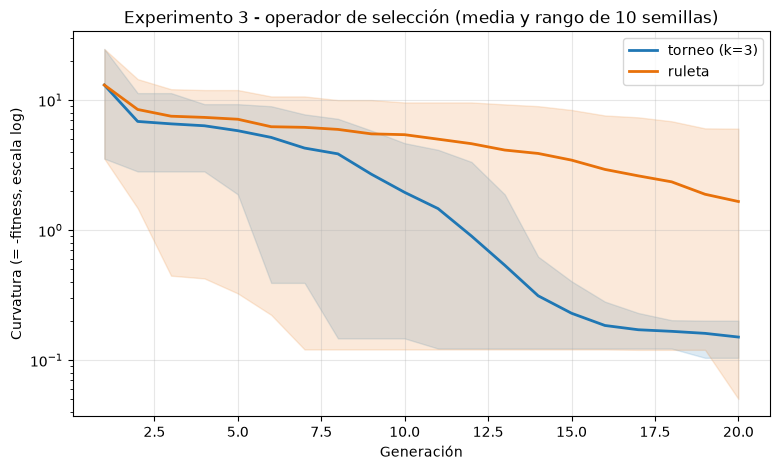

In [23]:
def correr_con(ga, **overrides):
    params = dict(population_size=100, lower_bound=-50, upper_bound=50,
                  generations=20, mutation_rate=1)
    params.update(overrides)

    curvas = []
    for s in SEEDS:
        random.seed(s)
        with contextlib.redirect_stdout(io.StringIO()):  
            _, bp, _ = ga(**params)
        curvas.append([fit for _, fit in bp])
    return curvas, [c[-1] for c in curvas]


with contextlib.redirect_stdout(io.StringIO()):
    random.seed(7); original = genetic_algorithm(20, -50, 50, 5, 1)[0]
random.seed(7); copia = genetic_algorithm_op(20, -50, 50, 5, 1, selection_fn=selection)[0]
assert original == copia, "la versión parametrizada no reproduce al GA original"
print("control de fidelidad: OK\n")

tabla = PrettyTable()
tabla.field_names = ["operador", "fitness medio", "mediana", "mejor", "peor", "desv"]

resultados_3 = []
for nombre, ga in (("torneo (k=3)", genetic_algorithm), ("ruleta", genetic_algorithm_roulette)):
    curvas, finales = correr_con(ga)
    resultados_3.append((nombre, curvas))
    tabla.add_row([nombre,
                   f"{statistics.mean(finales):.4f}",
                   f"{statistics.median(finales):.4f}",
                   f"{max(finales):.4f}",
                   f"{min(finales):.4f}",
                   f"{statistics.pstdev(finales):.4f}"])
print(tabla)

# Par categórico fijo: azul / naranja, separables también en visión con deficiencia de color.
COLOR_OP = {"torneo (k=3)": "#1f77b4", "ruleta": "#e8710a"}

fig, ax = plt.subplots(figsize=(9, 5))
for nombre, curvas in resultados_3:
    m = np.array(curvas) * -1                               # curvatura = -fitness (siempre > 0)
    gens = range(1, m.shape[1] + 1)
    ax.plot(gens, m.mean(axis=0), color=COLOR_OP[nombre], lw=2, label=nombre)
    ax.fill_between(gens, m.min(axis=0), m.max(axis=0), color=COLOR_OP[nombre], alpha=0.15)
ax.set_yscale('log')
ax.set_xlabel('Generación')
ax.set_ylabel('Curvatura (= -fitness, escala log)')
ax.set_title('Experimento 3 - operador de selección (media y rango de 10 semillas)')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

#### Control: la presión de selección

La comparación anterior dice *qué* operador anda mejor, no *por qué*. Para explicarlo hace falta una
magnitud comparable entre los dos. La que sirve es la **presión de selección**: cuántas copias del
mejor individuo deja la selección en la camada de padres.

Para el torneo esa cantidad tiene un valor exacto. El mejor individuo de la población gana cualquier
torneo en el que participe, así que gana con probabilidad `k/n` y como
la selección se repite `n` veces, el número esperado de copias es exactamente **`k`**. No depende
del tamaño de la población ni de los valores de fitness, solo del orden: `tournament_size` **es** la
presión de selección, expresada como un número de copias.

Para la ruleta no hay fórmula equivalente. Las copias esperadas valen
`n * peso_del_mejor / suma_de_pesos`, que depende por completo de cómo estén repartidos los fitness
en esa generación particular.

El control tiene entonces dos partes: barrer `tournament_size` para ver qué le hace la presión a
este problema, y después medir empíricamente la presión real de los dos operadores, generación por
generación.

In [24]:
from functools import partial


def ga_torneo(k):
    """Devuelve un GA que selecciona por torneo de tamaño k.
    functools.partial fija un argumento de una función y devuelve otra función
    ya configurada, como el .bind() de JavaScript."""
    seleccion_k = partial(selection, tournament_size=k)
    return lambda **kw: genetic_algorithm_op(selection_fn=seleccion_k, **kw)


tabla = PrettyTable()
tabla.field_names = ["operador", "copias esperadas del mejor", "fitness medio", "mediana", "peor", "desv"]

for k in (2, 3, 5, 10):
    _, finales = correr_con(ga_torneo(k))
    tabla.add_row([f"torneo k={k}", f"{k} (exacto)",
                   f"{statistics.mean(finales):.4f}",
                   f"{statistics.median(finales):.4f}",
                   f"{min(finales):.4f}",
                   f"{statistics.pstdev(finales):.4f}"])

_, finales_r = correr_con(genetic_algorithm_roulette)
tabla.add_row(["ruleta", "variable",
               f"{statistics.mean(finales_r):.4f}",
               f"{statistics.median(finales_r):.4f}",
               f"{min(finales_r):.4f}",
               f"{statistics.pstdev(finales_r):.4f}"])
print(tabla)

+-------------+----------------------------+---------------+---------+---------+--------+
|   operador  | copias esperadas del mejor | fitness medio | mediana |   peor  |  desv  |
+-------------+----------------------------+---------------+---------+---------+--------+
|  torneo k=2 |         2 (exacto)         |    -0.3053    | -0.2819 | -0.7304 | 0.2056 |
|  torneo k=3 |         3 (exacto)         |    -0.1506    | -0.1481 | -0.2013 | 0.0354 |
|  torneo k=5 |         5 (exacto)         |    -0.1330    | -0.1212 | -0.2135 | 0.0543 |
| torneo k=10 |        10 (exacto)         |    -0.0581    | -0.0535 | -0.1163 | 0.0341 |
|    ruleta   |          variable          |    -1.6594    | -0.4043 | -6.0323 | 2.1000 |
+-------------+----------------------------+---------------+---------+---------+--------+


copias esperadas del mejor individuo bajo torneo (la teoría dice exactamente k):
   k = 2   medido = 2.00
   k = 3   medido = 2.98


   k = 5   medido = 5.14
   k = 10  medido = 9.96



operador        presión media   rango (200 mediciones)   padres distintos
torneo (k=3)             3.00             [2.53, 3.63]               49.5
ruleta                   3.04            [1.22, 20.27]               59.3

ruleta, semilla por semilla (ordenado por presión media):
   semilla  8   presión media  2.01   ->   fitness final  -6.0323
   semilla  7   presión media  2.09   ->   fitness final  -4.5343
   semilla  9   presión media  2.39   ->   fitness final  -3.5524
   semilla  4   presión media  2.64   ->   fitness final  -0.6732
   semilla 10   presión media  2.73   ->   fitness final  -1.2436
   semilla  6   presión media  3.15   ->   fitness final  -0.1200
   semilla  1   presión media  3.22   ->   fitness final  -0.1354
   semilla  5   presión media  3.31   ->   fitness final  -0.0503
   semilla  3   presión media  4.17   ->   fitness final  -0.1319
   semilla  2   presión media  4.68   ->   fitness final  -0.1208

correlación de rangos (Spearman) entre presión media y fi

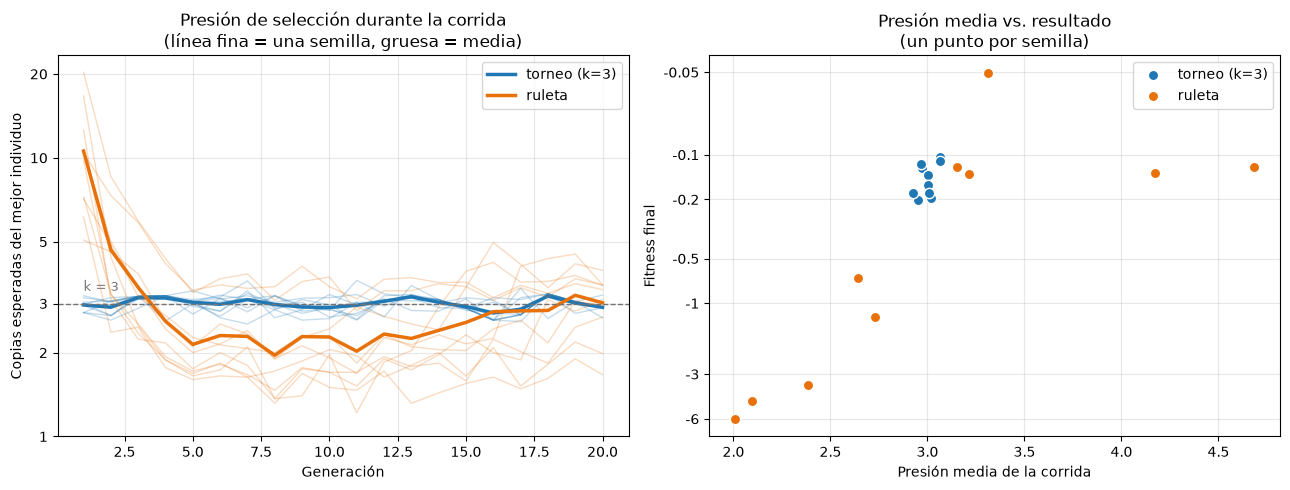

In [25]:
from matplotlib.ticker import FuncFormatter

numero = FuncFormatter(lambda v, _: f"{v:g}")      # etiquetas legibles en ejes logarítmicos


def presion_de_seleccion(population, fitnesses, selection_fn, reps=60):
    """Mide dos cosas del operador, promediando `reps` aplicaciones sobre la misma población:
      - copias esperadas del mejor individuo   -> la presión de selección
      - cantidad de padres distintos que pasan -> la diversidad que el operador deja pasar"""
    mejor = max(population, key=fitness_function)
    copias = distintos = 0
    for _ in range(reps):
        elegidos = selection_fn(population, fitnesses)
        copias += sum(1 for ind in elegidos if ind is mejor)
        distintos += len({id(ind) for ind in elegidos})
    return copias / reps, distintos / reps


# 1) Verificación empírica de la fórmula: bajo torneo, las copias esperadas del mejor valen k.
random.seed(7)
pob_test = create_initial_population(100, -50, 50)
fits_test = [fitness_function(ind) for ind in pob_test]
print("copias esperadas del mejor individuo bajo torneo (la teoría dice exactamente k):")
for k in (2, 3, 5, 10):
    medido, _ = presion_de_seleccion(pob_test, fits_test,
                                     partial(selection, tournament_size=k), reps=200)
    print(f"   k = {k:<3} medido = {medido:.2f}")

# 2) Presión real de los dos operadores, generación por generación y semilla por semilla.
presiones, diversidades, finales_op = {}, {}, {}
for nombre, sel_fn, ga in (("torneo (k=3)", selection, genetic_algorithm),
                           ("ruleta", selection_roulette, genetic_algorithm_roulette)):
    curvas_p, curvas_d, fins = [], [], []
    for s in SEEDS:
        random.seed(s)
        with contextlib.redirect_stdout(io.StringIO()):
            _, bp, pops = ga(100, -50, 50, 20, 1)
        serie_p, serie_d = [], []
        for g, pop in enumerate(pops):
            fits = [fitness_function(ind) for ind in pop]
            random.seed(50_000 + g)            # misma secuencia aleatoria para los dos operadores
            p, d = presion_de_seleccion(pop, fits, sel_fn)
            serie_p.append(p); serie_d.append(d)
        curvas_p.append(serie_p); curvas_d.append(serie_d); fins.append(bp[-1][1])
    presiones[nombre] = np.array(curvas_p)
    diversidades[nombre] = np.array(curvas_d)
    finales_op[nombre] = fins

print(f"\n{'operador':14s} {'presión media':>14s} {'rango (200 mediciones)':>24s} {'padres distintos':>18s}")
for nombre, m in presiones.items():
    print(f"{nombre:14s} {m.mean():>14.2f} {f'[{m.min():.2f}, {m.max():.2f}]':>24s} "
          f"{diversidades[nombre].mean():>18.1f}")

print("\nruleta, semilla por semilla (ordenado por presión media):")
for p, f, s in sorted(zip(presiones["ruleta"].mean(axis=1), finales_op["ruleta"], SEEDS)):
    print(f"   semilla {s:>2}   presión media {p:5.2f}   ->   fitness final {f:8.4f}")

rho = statistics.correlation(presiones["ruleta"].mean(axis=1).tolist(),
                             finales_op["ruleta"], method="ranked")
print(f"\ncorrelación de rangos (Spearman) entre presión media y fitness final: {rho:.2f}")

# 3) Gráficos.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

for nombre, m in presiones.items():
    gens = range(1, m.shape[1] + 1)
    for fila in m:                                     # una línea fina por semilla
        ax1.plot(gens, fila, color=COLOR_OP[nombre], alpha=0.25, lw=1)
    ax1.plot(gens, m.mean(axis=0), color=COLOR_OP[nombre], lw=2.5, label=nombre)
ax1.axhline(3, color='0.45', ls='--', lw=1)
ax1.text(1, 3.25, 'k = 3', ha='left', va='bottom', color='0.45', fontsize=9)
ax1.set_yscale('log')
ax1.set_yticks([1, 2, 3, 5, 10, 20]); ax1.minorticks_off()
ax1.yaxis.set_major_formatter(numero)
ax1.set_xlabel('Generación')
ax1.set_ylabel('Copias esperadas del mejor individuo')
ax1.set_title('Presión de selección durante la corrida\n(línea fina = una semilla, gruesa = media)')
ax1.legend(); ax1.grid(alpha=0.3)

for nombre, m in presiones.items():
    ax2.scatter(m.mean(axis=1), finales_op[nombre], color=COLOR_OP[nombre], s=55,
                edgecolor='white', linewidth=1, label=nombre, zorder=3)
ax2.set_yscale('symlog', linthresh=0.1)
ax2.set_yticks([-6, -3, -1, -0.5, -0.2, -0.1, -0.05]); ax2.minorticks_off()
ax2.yaxis.set_major_formatter(numero)
ax2.set_xlabel('Presión media de la corrida')
ax2.set_ylabel('Fitness final')
ax2.set_title('Presión media vs. resultado\n(un punto por semilla)')
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout(); plt.show()

**Análisis del Experimento 3**

Reemplazar el torneo por la ruleta **empeora el resultado medio en un orden de magnitud**: el
fitness final promedio pasa de **-0.1506** a **-1.6594**. Pero quedarse con la media induce a error,
porque la mediana de la ruleta es -0.4043 y su **mejor** corrida (-0.0503) es mejor que la mejor del
torneo (-0.1042). La ruleta no es un operador peor: es un operador **inconsistente**. El desvío lo
dice sin ambigüedad: **2.1000 contra 0.0354**, casi sesenta veces más dispersión. Cinco de las diez
semillas terminan entre -0.135 y -0.050, a la altura del torneo o mejor, y las otras cinco entre
-0.673 y -6.032.

La explicación natural de esa inconsistencia sería la convergencia prematura: la ruleta amplifica
demasiado al mejor individuo, la población pierde diversidad y el algoritmo se queda clavado. **Los
datos no la sostienen.** El diagnóstico mide cuántos padres *distintos* deja pasar cada operador, y
la ruleta deja **59.3** contra **49.5** del torneo: conserva *más* diversidad, no menos.

Lo que sí explica el resultado es la **presión de selección**, medida como el número esperado de
copias del mejor individuo que la selección deposita en la camada de padres. Para el torneo esa
cantidad tiene un valor exacto y deducible: el mejor individuo gana cualquier torneo en el que
participe, entra en la muestra con probabilidad `k/n`, y como la selección se repite `n` veces, el
valor esperado es exactamente **`k`**, sin depender del tamaño de la población ni de los valores de
fitness. La medición empírica lo confirma: 2.00, 2.98, 5.14 y 9.96 copias para `k` igual a 2, 3, 5 y
10. En otras palabras, **`tournament_size` *es* la presión de selección**, expresada directamente
como un número de copias.

Sobre las 200 mediciones del experimento (10 semillas × 20 generaciones), la presión del torneo se
mantuvo en el rango **[2.53, 3.63]**, siempre alrededor de 3; la dispersión que se ve es ruido de
medición, no deriva. La ruleta, en promedio global, tiene prácticamente **la misma** presión:
**3.04**. Pero su rango sobre las mismas 200 mediciones es **[1.22, 20.27]**. La presión de la
ruleta no es un parámetro que el programador elija, sino una consecuencia emergente de cómo estén
repartidos los fitness en esa generación particular, y se mueve de forma impredecible a lo largo de
la corrida: arranca cerca de 11 copias en la primera generación, cuando los fitness difieren en
órdenes de magnitud, y cae a poco más de 2 una vez que la población se homogeneiza.

Ahí está el daño, y la comparación entre semillas lo confirma: la correlación de rangos (Spearman)
entre la presión media de cada corrida y su fitness final es **ρ = 0.85**. Las cinco semillas cuya
presión media superó 3.1 terminaron todas entre -0.135 y -0.050; las cinco que quedaron por debajo
de 2.75 terminaron todas entre -0.673 y -6.032. No hay un solo caso cruzado. El panel derecho del
gráfico lo muestra como una nube ordenada para la ruleta y un único punto apretado para el torneo.

El barrido de `tournament_size` cierra el argumento mostrando que este problema **premia la presión
alta**: -0.3053 con `k`=2, -0.1506 con `k`=3, -0.1330 con `k`=5 y **-0.0581 con `k`=10**, una mejora
monótona. Es coherente con lo que ya se sabía del paisaje de búsqueda: el óptimo está en el borde
`a → 0⁺` y solo se alcanza de forma asintótica, caminando con pasos de mutación de ±1, de modo que
lo que el algoritmo necesita es explotar agresivamente al mejor individuo en cada generación. La
ruleta no puede garantizar eso, porque su presión no es una decisión de diseño sino un emergente del
paisaje.

La conclusión práctica es que **el torneo conviene no por ser más selectivo, sino por ser
predecible**. Su presión es un número que se elige y que no cambia aunque el fitness se mueva varios
órdenes de magnitud entre la primera generación y la última. La ruleta, además, obliga a tomar una
decisión que no forma parte de la definición del operador (cómo transformar un fitness negativo en
un peso no negativo) y de la que los resultados dependen. Un operador cuyo comportamiento efectivo
queda determinado por una elección de implementación no documentada es justamente lo que no se
quiere en un algoritmo de optimización.

### Experimento 4 - Operador de crossover: punto simple vs. aritmético

El cuarto experimento cambia el otro operador de recombinación. La implementación de referencia usa
**crossover aritmético**: sortea un `alpha` y devuelve dos combinaciones convexas de los padres.

```
alpha = random.random()
hijo1 = alpha * padre1 + (1 - alpha) * padre2
hijo2 = alpha * padre2 + (1 - alpha) * padre1
```

Como `alpha` es el mismo para los tres genes, los hijos caen sobre el **segmento** que une a los dos
padres en el espacio `(a, b, c)`. De ahí se sigue la propiedad que ya apareció en el Experimento 2:
todo hijo queda dentro de la envolvente convexa de la población, así que el crossover aritmético
**nunca puede generar un `a` menor que el menor `a` presente**. Solo la mutación puede.

El **crossover de punto simple** es el operador clásico de los algoritmos genéticos: corta los dos
cromosomas en un punto y los intercambia. Con tres genes el corte va después del primero o del
segundo.

```
punto = 1:   hijo1 = (a1, b2, c2)      hijo2 = (a2, b1, c1)
punto = 2:   hijo1 = (a1, b1, c2)      hijo2 = (a2, b2, c1)
```

No promedia nada: cada gen del hijo es una copia exacta del gen de uno de los padres. **No crea
valores nuevos**, solo cambia qué genes viajan juntos. Eso le da la propiedad opuesta a la del
aritmético: no puede interpolar, pero tampoco destruye un buen valor diluyéndolo en un promedio.

Se agrega un tercer brazo de control, **sin crossover**, donde los hijos son copias de los padres.
Sirve para medir cuánto aporta realmente la recombinación en este problema: con ese brazo el
algoritmo queda reducido a selección + elitismo + mutación, es decir a una búsqueda local paralela.

In [26]:
def crossover_1point(parent1, parent2):
    """Crossover de punto simple: corta los dos cromosomas en un punto y los intercambia."""
    point = random.randint(1, len(parent1) - 1)   # randint incluye AMBOS extremos: acá 1 o 2
    return parent1[:point] + parent2[point:], parent2[:point] + parent1[point:]


def crossover_ninguno(parent1, parent2):
    """Control: sin recombinación, los hijos son copias de los padres."""
    return parent1, parent2


# Demostración de la diferencia de fondo entre los dos operadores.
p1, p2 = (1.0, 2.0, 3.0), (-9.0, -8.0, -7.0)
random.seed(3)
print("padres:       ", p1, p2, "\n")
print("aritmético:   ", crossover(p1, p2))
print("              -> valores nuevos: ninguno de esos números estaba en los padres\n")
for _ in range(3):
    print("punto simple: ", crossover_1point(p1, p2))
print("              -> todos los valores vienen tal cual de alguno de los dos padres")

padres:        (1.0, 2.0, 3.0) (-9.0, -8.0, -7.0) 

aritmético:    ((-6.620353729081087, -5.620353729081087, -4.620353729081086), (-1.3796462709189135, -0.3796462709189137, 0.6203537290810861))
              -> valores nuevos: ninguno de esos números estaba en los padres

punto simple:  ((1.0, -8.0, -7.0), (-9.0, 2.0, 3.0))
punto simple:  ((1.0, 2.0, -7.0), (-9.0, -8.0, 3.0))
punto simple:  ((1.0, 2.0, -7.0), (-9.0, -8.0, 3.0))
              -> todos los valores vienen tal cual de alguno de los dos padres


+--------------+---------------+---------+---------+---------+--------+
|  crossover   | fitness medio | mediana |  mejor  |   peor  |  desv  |
+--------------+---------------+---------+---------+---------+--------+
|  aritmético  |    -0.1506    | -0.1481 | -0.1042 | -0.2013 | 0.0354 |
| punto simple |    -0.0987    | -0.0855 | -0.0359 | -0.2527 | 0.0561 |
|   ninguno    |    -0.4236    | -0.1045 | -0.0362 | -3.2252 | 0.9357 |
+--------------+---------------+---------+---------+---------+--------+


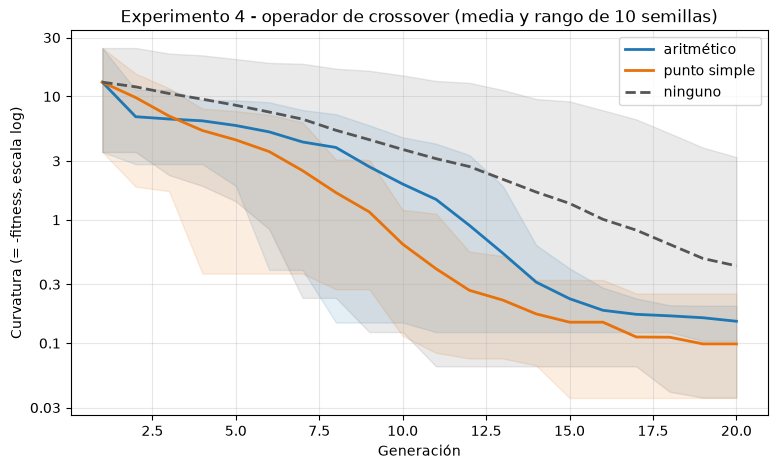

In [27]:
COLOR_CX = {"aritmético": "#1f77b4", "punto simple": "#e8710a", "ninguno": "#555555"}
ESTILO_CX = {"aritmético": "-", "punto simple": "-", "ninguno": "--"}   # el control va punteado

OPERADORES_CX = (("aritmético", crossover), ("punto simple", crossover_1point),
                 ("ninguno", crossover_ninguno))

tabla = PrettyTable()
tabla.field_names = ["crossover", "fitness medio", "mediana", "mejor", "peor", "desv"]

resultados_4 = []
for nombre, cf in OPERADORES_CX:
    curvas, finales = correr_con(genetic_algorithm_op, crossover_fn=cf)
    resultados_4.append((nombre, curvas))
    tabla.add_row([nombre,
                   f"{statistics.mean(finales):.4f}",
                   f"{statistics.median(finales):.4f}",
                   f"{max(finales):.4f}",
                   f"{min(finales):.4f}",
                   f"{statistics.pstdev(finales):.4f}"])
print(tabla)

fig, ax = plt.subplots(figsize=(9, 5))
for nombre, curvas in resultados_4:
    m = np.array(curvas) * -1                        # curvatura = -fitness (siempre > 0)
    gens = range(1, m.shape[1] + 1)
    ax.plot(gens, m.mean(axis=0), color=COLOR_CX[nombre], ls=ESTILO_CX[nombre], lw=2, label=nombre)
    ax.fill_between(gens, m.min(axis=0), m.max(axis=0), color=COLOR_CX[nombre], alpha=0.12)
ax.set_yscale('log')
ax.set_yticks([0.03, 0.1, 0.3, 1, 3, 10, 30]); ax.minorticks_off()
ax.yaxis.set_major_formatter(numero)
ax.set_xlabel('Generación')
ax.set_ylabel('Curvatura (= -fitness, escala log)')
ax.set_title('Experimento 4 - operador de crossover (media y rango de 10 semillas)')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

#### Control: qué le hace cada operador a la diversidad

La diferencia de fondo entre los dos operadores se puede cuantificar de forma exacta. Sea `σ²` la
varianza de un gen en la población. El crossover aritmético produce `hijo = α·p1 + (1-α)·p2` con
`α` uniforme en [0, 1], de modo que, tomando los padres como independientes:

```
Var(hijo) = E[α²]·σ² + E[(1-α)²]·σ² = (1/3 + 1/3)·σ² = (2/3)·σ²
```

Es decir que **el crossover aritmético destruye un tercio de la varianza de la población en cada
generación**, sin depender de la forma de la distribución.

El de punto simple no destruye nada. Para cualquier punto de corte, cada hijo hereda cada gen
intacto de uno de los dos padres, y entre los dos hijos los dos valores del padre aparecen
exactamente una vez. El **multiconjunto** de valores de cada gen queda idéntico: el factor vale
exactamente 1.

De eso se deduce también la diversidad de equilibrio. Con `mutation_rate = 1`, la mutación suma a
cada gen un valor uniforme en [-1, 1], cuya varianza es `(2)²/12 = 1/3`. Para el aritmético queda
`σ²ₜ₊₁ = (2/3)·σ²ₜ + 1/3`, cuyo punto fijo es `σ² = 1`, o sea `σ = 1`. Para el de punto simple no
hay término de contracción y la diversidad queda acotada únicamente por la selección.

+--------------+-------------+-------------+-------------+-------------+
|  crossover   | factor en a | factor en b | factor en c |    teoría   |
+--------------+-------------+-------------+-------------+-------------+
|  aritmético  |    0.664    |    0.668    |    0.660    | 2/3 = 0.667 |
| punto simple |    1.000    |    1.000    |    1.000    |  1 (exacto) |
|   ninguno    |    1.000    |    1.000    |    1.000    |  1 (exacto) |
+--------------+-------------+-------------+-------------+-------------+

crossover         hijos (de 100) que conservan el mejor a
aritmético                                           0.29
punto simple                                         6.00
ninguno                                              6.00



crossover        desvío del gen a en la última generación
aritmético                                          0.656
punto simple                                        0.722
ninguno                                             0.730


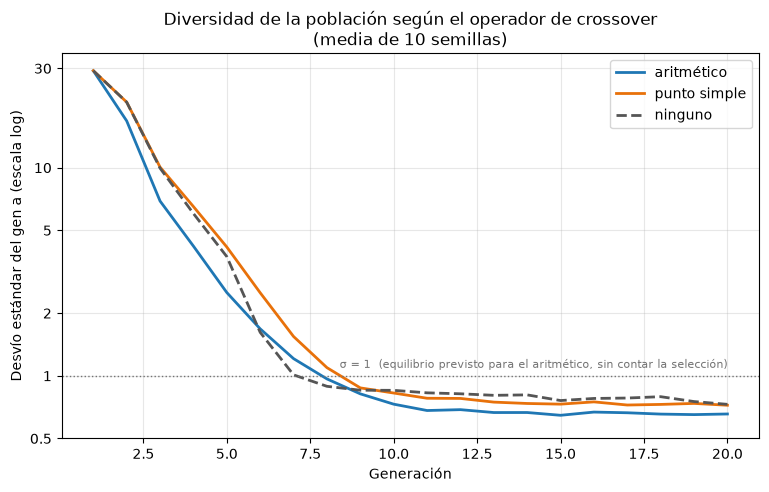

In [28]:
def factor_de_contraccion(crossover_fn, poblacion, reps=300):
    """Por cuánto multiplica el operador la varianza de cada gen de la población.
    Se aplica el crossover tal como lo hace el GA (de a pares por posición) pero sin selección
    ni mutación, para aislar el efecto del operador."""
    antes = np.var(np.array(poblacion), axis=0)
    acum = np.zeros(len(poblacion[0]))
    for _ in range(reps):
        p = poblacion[:]
        random.shuffle(p)                                   # el apareamiento del GA es por posición
        hijos = []
        for i in range(0, len(p), 2):
            c1, c2 = crossover_fn(p[i], p[i + 1])
            hijos += [c1, c2]
        acum += np.var(np.array(hijos), axis=0)
    return acum / reps / antes


random.seed(11)
poblacion_test = create_initial_population(100, -50, 50)

tabla = PrettyTable()
tabla.field_names = ["crossover", "factor en a", "factor en b", "factor en c", "teoría"]
for (nombre, cf), teoria in zip(OPERADORES_CX, ("2/3 = 0.667", "1 (exacto)", "1 (exacto)")):
    f = factor_de_contraccion(cf, poblacion_test)
    tabla.add_row([nombre, f"{f[0]:.3f}", f"{f[1]:.3f}", f"{f[2]:.3f}", teoria])
print(tabla)

def supervivencia_del_mejor_gen(crossover_fn, pool, reps=200):
    """Cuántos de los 100 hijos conservan EXACTAMENTE el valor de 'a' del mejor padre.
    Mide si el operador preserva un buen gen o lo diluye en un promedio."""
    mejor_a = max(pool, key=fitness_function)[0]
    total = 0
    for _ in range(reps):
        p = pool[:]
        random.shuffle(p)
        hijos = []
        for i in range(0, len(p), 2):
            c1, c2 = crossover_fn(p[i], p[i + 1])
            hijos += [c1, c2]
        total += sum(1 for h in hijos if h[0] == mejor_a)
    return total / reps


# Camada de padres realista: la de la generación 10 de una corrida normal.
random.seed(1)
_, _, pops_ref = genetic_algorithm_op(100, -50, 50, 20, 1)
fits_ref = [fitness_function(ind) for ind in pops_ref[9]]
random.seed(99)
pool_ref = selection(pops_ref[9], fits_ref)

print(f"\n{'crossover':14s} {'hijos (de 100) que conservan el mejor a':>42s}")
for nombre, cf in OPERADORES_CX:
    print(f"{nombre:14s} {supervivencia_del_mejor_gen(cf, pool_ref):>42.2f}")

# Diversidad real del gen 'a' a lo largo de la corrida, ya con selección y mutación actuando.
diversidad_a = {}
for nombre, cf in OPERADORES_CX:
    series = []
    for s in SEEDS:
        random.seed(s)
        _, _, pops = genetic_algorithm_op(100, -50, 50, 20, 1, crossover_fn=cf)
        series.append([statistics.pstdev([ind[0] for ind in pop]) for pop in pops])
    diversidad_a[nombre] = np.array(series)

print(f"\n{'crossover':14s} {'desvío del gen a en la última generación':>42s}")
for nombre, m in diversidad_a.items():
    print(f"{nombre:14s} {m[:, -1].mean():>42.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
for nombre, m in diversidad_a.items():
    ax.plot(range(1, m.shape[1] + 1), m.mean(axis=0),
            color=COLOR_CX[nombre], ls=ESTILO_CX[nombre], lw=2, label=nombre)
ax.axhline(1.0, color='0.45', ls=':', lw=1)
ax.text(20, 1.06, 'σ = 1  (equilibrio previsto para el aritmético, sin contar la selección)',
        ha='right', va='bottom', color='0.45', fontsize=8)
ax.set_yscale('log')
ax.set_yticks([0.5, 1, 2, 5, 10, 30]); ax.minorticks_off()
ax.yaxis.set_major_formatter(numero)
ax.set_xlabel('Generación')
ax.set_ylabel('Desvío estándar del gen a (escala log)')
ax.set_title('Diversidad de la población según el operador de crossover\n(media de 10 semillas)')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

#### Control: el crossover aislado, sin mutación

El Experimento 2 ya había mostrado que con `mutation_rate = 0` el algoritmo queda estancado. Repetir
ese caso con los tres operadores sirve para ver **qué puede hacer la recombinación por sí sola**,
sin que la mutación le tape los efectos.

La predicción es asimétrica. El aritmético, sin mutación, todavía puede crear valores nuevos
interpolando, aunque nunca por fuera de la envolvente convexa de la población. El de punto simple
no puede crear absolutamente nada: el multiconjunto de valores de cada gen queda fijo en el de la
población inicial, así que la búsqueda se reduce a elegir entre las combinaciones de los 100 valores
iniciales de `a`, los 100 de `b` y los 100 de `c`. Y el brazo sin crossover no puede hacer nada en
absoluto: la población solo pierde individuos por selección.

In [29]:
tabla = PrettyTable()
tabla.field_names = ["crossover", "fitness medio", "mediana", "mejor", "peor", "desv", "div(a) final"]
for nombre, cf in OPERADORES_CX:
    finales, divs = [], []
    for s in SEEDS:
        random.seed(s)
        _, bp, pops = genetic_algorithm_op(100, -50, 50, 20, 0, crossover_fn=cf)
        finales.append(bp[-1][1])
        divs.append(statistics.pstdev([ind[0] for ind in pops[-1]]))
    tabla.add_row([nombre,
                   f"{statistics.mean(finales):.4f}",
                   f"{statistics.median(finales):.4f}",
                   f"{max(finales):.4f}",
                   f"{min(finales):.4f}",
                   f"{statistics.pstdev(finales):.4f}",
                   f"{statistics.mean(divs):.3f}"])
print("mutation_rate = 0 (solo selección, elitismo y crossover)")
print(tabla)

mutation_rate = 0 (solo selección, elitismo y crossover)
+--------------+---------------+----------+---------+----------+--------+--------------+
|  crossover   | fitness medio | mediana  |  mejor  |   peor   |  desv  | div(a) final |
+--------------+---------------+----------+---------+----------+--------+--------------+
|  aritmético  |    -7.4217    | -6.7594  | -3.0543 | -12.4863 | 2.9498 |    0.004     |
| punto simple |    -6.8386    | -6.7499  | -0.8581 | -11.3224 | 3.1903 |    0.000     |
|   ninguno    |    -13.0585   | -11.0562 | -3.5469 | -24.7113 | 6.2154 |    0.000     |
+--------------+---------------+----------+---------+----------+--------+--------------+


**Análisis del Experimento 4**

El crossover de punto simple **mejora el resultado respecto del aritmético**: el fitness medio pasa
de **-0.1506** a **-0.0987**, un 34 % mejor, y la mejor corrida pasa de -0.1042 a **-0.0359**. La
gráfica muestra que la ventaja no aparece al final sino que se sostiene desde la cuarta generación
en adelante. El precio es un leve aumento de la dispersión (desvío 0.0561 contra 0.0354, y peor
corrida -0.2527 contra -0.2013), de modo que la mejora es real pero no gratuita.

El tercer brazo, **sin crossover**, da el resultado más revelador del experimento. Su fitness medio
es -0.4236, claramente el peor, pero su **mediana es -0.1045**, prácticamente igual a la del
aritmético (-0.1481) y a la del punto simple (-0.0855). Lo que arrastra la media es una única
corrida catastrófica (-3.2252), y eso se refleja en un desvío de 0.9357 contra 0.03 a 0.06 de los
otros dos. La lectura es incómoda para el algoritmo: en este problema **el crossover casi no mejora
la corrida típica; lo que hace es evitar los desastres**. Sin recombinación el algoritmo es una
búsqueda local paralela con elitismo, y eso ya alcanza para llegar a -0.10 la mitad de las veces.

El mecanismo que separa a los dos operadores se puede medir de forma exacta. El factor por el que
cada uno multiplica la varianza de un gen en la población resultó **0.664, 0.668 y 0.660** para el
aritmético, contra el `2/3 = 0.667` que predice la cuenta, y exactamente **1.000** en los tres genes
para el de punto simple. Es decir que el crossover aritmético destruye un tercio de la varianza de
la población en cada generación, mientras que el de punto simple no destruye nada: se limita a
reordenar qué genes viajan juntos, dejando intacto el multiconjunto de valores de cada gen.

Ahora bien, **ese factor explica la dirección del resultado pero no su magnitud**. La diversidad que
efectivamente se observa al final de la corrida es 0.656 con el aritmético contra 0.722 con el de
punto simple: una diferencia del 10 %, mucho menor que la que haría esperar un factor de 2/3 aplicado
veinte veces. El motivo es que la selección es un contractor mucho más fuerte que el crossover, y es
ella la que fija el nivel de diversidad; la gráfica lo muestra con las tres curvas estabilizándose
en valores parecidos. El equilibrio previsto para el aritmético ignorando la selección era `σ = 1`,
y el valor real queda por debajo.

Lo que sí distingue a los operadores en la práctica es **qué le pasa a un gen bueno**. La medición
sobre una camada de padres real de la generación 10 lo muestra directamente: de los 100 hijos, con
punto simple **6.00** conservan exactamente el valor de `a` del mejor padre, y con el aritmético
apenas **0.29**. El punto simple preserva el multiconjunto completo, así que los seis ejemplares del
mejor `a` que la selección había puesto en la camada pasan íntegros a la descendencia. El aritmético
los **diluye**: toda combinación convexa con un compañero peor da un valor intermedio distinto, y
ese 0.29 corresponde a los pocos pares en los que los dos padres resultaron ser copias del mismo
individuo. Con el aritmético, el único ejemplar que sobrevive intacto es el que preserva el
elitismo. Como el óptimo de este problema está en el borde `a → 0⁺` y se alcanza
por acumulación de pasos chicos de mutación, conservar intacto el `a` más chico encontrado hasta el
momento vale más que poder interpolar entre dos valores.

El control sin mutación confirma la otra cara. Con `mutation_rate = 0` los tres brazos se estancan:
-7.4217 el aritmético, -6.8386 el de punto simple y -13.0585 sin crossover. El último es el caso
puro: sin mutación y sin recombinación la población solo puede perder individuos, así que el
resultado es simplemente el mejor de la población inicial. Los otros dos muestran que la
recombinación sí aporta algo (de -13.06 a -7), pero que ninguno de los dos puede acercarse al óptimo
por sí solo. La diversidad final en los tres casos es prácticamente **0.000**: la población colapsa
a copias de un único individuo. Para el punto simple el estancamiento es además estructural, porque
el operador no puede crear valores nuevos: el multiconjunto de valores de cada gen queda congelado
en el de la población inicial y la búsqueda se reduce a elegir entre combinaciones de esos 100
valores. Esto refuerza la conclusión del Experimento 2: **en esta implementación el motor de la
búsqueda es la mutación, y el crossover es un mecanismo secundario de mezcla**.

---
## Parte 4 - Preguntas de reflexión final

### 4.1 ¿En qué se diferencia un algoritmo genético de una búsqueda local (como hill climbing)?

Antes de responder conviene medirlo. El *hill climbing* mantiene **una sola** solución y se mueve a
un vecino únicamente si mejora. Se lo compara contra el GA dándole exactamente el mismo presupuesto
(2000 evaluaciones de fitness, que es `population_size × generations` de la configuración base) y
exactamente el mismo paso de perturbación que usa la mutación del GA, `uniform(-1, 1)`.

In [30]:
def hill_climbing(evaluaciones=2000, lower_bound=-50, upper_bound=50, paso=1.0,
                  arranque_factible=False):
    """Búsqueda local clásica: una única solución, se acepta el vecino solo si mejora.
    Mismo paso de perturbación (±1) y mismo presupuesto de evaluaciones que el GA."""
    a0 = random.uniform(0.001, upper_bound) if arranque_factible \
         else random.uniform(lower_bound, upper_bound)
    actual = (a0, random.uniform(lower_bound, upper_bound), random.uniform(lower_bound, upper_bound))
    f_actual = fitness_function(actual)

    for _ in range(evaluaciones - 1):
        vecino = tuple(max(min(g + random.uniform(-paso, paso), upper_bound), lower_bound)
                       for g in actual)
        f = fitness_function(vecino)
        if f > f_actual:                       # solo se acepta si mejora estrictamente
            actual, f_actual = vecino, f
    return f_actual


def resumen(valores):
    """Resume una lista de fitness finales separando las corridas que murieron en -inf."""
    vivos = [v for v in valores if v != -float('inf')]
    muertas = f"{len(valores) - len(vivos)}/{len(valores)}"
    if not vivos:
        return ["-"] * 5 + [muertas]
    return [f"{statistics.mean(vivos):.4f}", f"{statistics.median(vivos):.4f}",
            f"{max(vivos):.4f}", f"{min(vivos):.4f}", f"{statistics.pstdev(vivos):.4f}", muertas]


tabla = PrettyTable()
tabla.field_names = ["método", "fitness medio", "mediana", "mejor", "peor", "desv",
                     "corridas muertas"]

hc_aleatorio, hc_factible = [], []
for s in SEEDS:
    random.seed(s); hc_aleatorio.append(hill_climbing())
    random.seed(s); hc_factible.append(hill_climbing(arranque_factible=True))

tabla.add_row(["hill climbing (arranque aleatorio)"] + resumen(hc_aleatorio))
tabla.add_row(["hill climbing (arranque con a > 0)"] + resumen(hc_factible))
_, finales_ga = correr_con(genetic_algorithm)
tabla.add_row(["GA (torneo + crossover aritmético)"] + resumen(finales_ga))

print("2000 evaluaciones de fitness para cada método, 10 semillas, mismo paso ±1")
print(tabla)

2000 evaluaciones de fitness para cada método, 10 semillas, mismo paso ±1
+------------------------------------+---------------+---------+---------+---------+--------+------------------+
|               método               | fitness medio | mediana |  mejor  |   peor  |  desv  | corridas muertas |
+------------------------------------+---------------+---------+---------+---------+--------+------------------+
| hill climbing (arranque aleatorio) |    -0.0757    | -0.0706 | -0.0350 | -0.1267 | 0.0355 |       6/10       |
| hill climbing (arranque con a > 0) |    -0.0806    | -0.0790 | -0.0489 | -0.1216 | 0.0248 |       0/10       |
| GA (torneo + crossover aritmético) |    -0.1506    | -0.1481 | -0.1042 | -0.2013 | 0.0354 |       0/10       |
+------------------------------------+---------------+---------+---------+---------+--------+------------------+


Las diferencias de fondo son tres, y conviene separarlas de sus consecuencias.

1. **Una solución contra una población.** El hill climbing recorre el espacio con un único punto; el
   GA mantiene `population_size` soluciones en paralelo y hace que compitan entre sí.
2. **Existe la recombinación.** El crossover combina información de **dos** soluciones distintas, un
   operador que sencillamente no tiene análogo en una búsqueda local: no hay con quién recombinar.
3. **La aceptación es poblacional y estocástica.** El hill climbing clásico solo acepta movimientos
   que mejoran, de modo que nunca baja. En el GA un individuo peor puede sobrevivir, porque la
   selección es un sorteo y no un `if mejor`.

La consecuencia que se suele citar es que el GA puede **escapar de óptimos locales** y el hill
climbing no. **En este problema esa ventaja no se materializa, y los números lo muestran:** con el
mismo presupuesto de 2000 evaluaciones, un único hill climber llega a **-0.0806** y el GA completo a
**-0.1506**. La búsqueda local es casi el doble de buena, y además más consistente (desvío 0.0248
contra 0.0354).

El motivo es que **este paisaje no tiene óptimos locales de los que escapar**. Como se dedujo en la
Parte 2, el fitness equivale a `-(2a + b²/(2a))`, que en toda la región factible `a > 0` crece de
forma monótona hacia la esquina `a → 0⁺`, `b → 0`. No hay ningún máximo local interior donde
quedarse trabado. Toda la maquinaria del GA (población, selección, recombinación) es, para este
problema, costo sin beneficio.

Lo que la población **sí** compró es otra cosa, y aparece en la última columna de la tabla: con
arranque aleatorio, **6 de las 10 corridas del hill climbing mueren en `-inf` y no se recuperan
nunca**. Si la solución inicial cae con `a ≤ 0`, su fitness es `-inf`, y un paso de ±1 casi nunca
alcanza para cruzar a la región factible; como el vecino también vale `-inf`, la condición
`f > f_actual` es falsa y el movimiento se rechaza. La búsqueda queda congelada sobre una **meseta
sin gradiente**. El GA nunca sufre esto: arranca con unos 50 individuos factibles de 100, y la
selección descarta a los demás sin que nadie tenga que escapar de ningún lado.

En resumen: la diferencia que importó acá **no fue la capacidad de escapar de óptimos locales, sino
la robustez frente a una inicialización infactible**. Y esa robustez se podría haber conseguido más
barato arreglando la penalización, como se discute en la pregunta 4.4.

### 4.2 Menciona dos ventajas y dos desventajas de los algoritmos genéticos

**Ventaja 1: No necesita derivadas, continuidad ni una forma analítica del objetivo.** Al GA le
alcanza con poder *evaluar* el fitness. El de este laboratorio es un buen ejemplo: es discontinuo,
porque salta a `-inf` en cuanto `a ≤ 0`, y eso no le molestó en ninguna corrida. Un método basado en
gradiente no se puede aplicar sobre una función así sin reformularla primero.

**Ventaja 2: La población da robustez frente al azar de la inicialización.** Es el hallazgo que más
se repitió en la Parte 3. En el Experimento 1, pasar de 50 a 200 individuos mejoró la media de -1.90
a -0.07, pero sobre todo bajó el desvío de **3.64 a 0.034**: lo que compra el tamaño de la población
no es tanto calidad como **confiabilidad**. Y en la pregunta 4.1 se vio la versión extrema del mismo
efecto: el hill climber murió en 6 de 10 corridas por una mala inicialización, y el GA en ninguna.

**Desventaja 1: Muchos hiperparámetros, acoplados entre sí, sin teoría que los fije.** El control
del Experimento 2 es la demostración más clara: con paso de mutación ±1 la mejor tasa es 0.8, y con
paso ±50 **el efecto se invierte** y la mejor pasa a ser 0.1. O sea que la pregunta "¿cuál es la
tasa de mutación óptima?" **no tiene respuesta** si no se fija antes la magnitud del paso. Lo mismo
con el presupuesto: en el Experimento 1, repartir 4000 evaluaciones como 400×10 en vez de 50×80
hunde el resultado de -0.047 a -1.39. Encontrar una configuración que ande cuesta, en cómputo, más
que resolver el problema.

**Desventaja 2: Costo por evaluación y ausencia de garantías.** El GA gastó 2000 evaluaciones para
llegar a -0.1506 en un problema donde una búsqueda local llega a -0.0806 con el mismo presupuesto.
Además no hay criterio de parada (el loop simplemente corre un número fijo de generaciones) ni
ninguna cota sobre qué tan lejos del óptimo quedó el resultado. Se sabe que la respuesta es buena
solo porque en este caso el óptimo se conoce analíticamente, lo cual en un problema real no pasa.

### 4.3 ¿En qué problemas reales serían útiles los algoritmos genéticos?

La pregunta más útil no es *en cuáles* sino *bajo qué condiciones*, y este laboratorio da el
criterio por contraste: acá el GA perdió contra una búsqueda local porque el problema es continuo,
de tres dimensiones, derivable y sin óptimos locales. Un algoritmo genético se justifica cuando pasa
lo contrario:

- **El objetivo es una caja negra sin derivadas**, porque viene de una simulación, de un modelo
  numérico o de un experimento físico.
- **Hay muchos óptimos locales**, que es justamente lo que este problema no tenía.
- **El espacio es combinatorio, discreto o mixto**, donde "moverse un poquito" ni siquiera está bien
  definido y por lo tanto el gradiente no existe como concepto.
- **Se puede pagar un presupuesto grande de evaluaciones**, porque el GA es caro por evaluación.
- **Interesa un conjunto diverso de buenas soluciones** y no una sola, que es el terreno natural de
  las variantes multiobjetivo (NSGA-II y parientes).

Ejemplos concretos que cumplen esas condiciones:

- **Diseño de antenas.** El caso más citado es la antena evolucionada de la misión **ST5 de la NASA**
  (2006), diseñada con un algoritmo evolutivo. La geometría resultante no se parece a nada que un
  ingeniero hubiera dibujado a mano, y el fitness salía de simular el patrón de radiación: caja
  negra pura.
- **Ruteo de vehículos y variantes del viajante de comercio** con ventanas horarias y capacidades.
  Espacio combinatorio, NP-duro, y el costo de una solución se obtiene simulando las rutas.
- **Scheduling**: asignación de turnos de personal, armado de horarios de aulas, secuenciamiento de
  trabajos en una planta. Restricciones duras y blandas mezcladas, y un espacio discreto enorme.
- **Ajuste de hiperparámetros y neuroevolución.** El espacio es mixto (enteros, reales y opciones
  categóricas) y cada evaluación cuesta un entrenamiento completo.
- **Diseño estructural y optimización topológica**, donde el fitness sale de una simulación por
  elementos finitos y el espacio de formas admisibles es gigantesco.

El denominador común es que en todos ellos **no existe un método especializado que explote la
estructura del problema**. Cuando ese método existe, como el vértice `x = -b/2a` para una parábola
o el gradiente para una función suave, conviene usarlo: es más rápido y da garantías que el GA no
puede ofrecer.

### 4.4 ¿Qué mejorarías en este código si quisieras aplicarlo a un problema más complejo?

Las tres primeras observaciones se pueden demostrar ejecutándolas, así que conviene medirlas antes
de enumerarlas.

In [31]:
import time


class ContadorDeFitness:
    """Envuelve a fitness_function para contar cuántas veces se la llama realmente."""
    def __init__(self, f): self.f, self.n = f, 0
    def __call__(self, x): self.n += 1; return self.f(x)


# (a) ¿Cuántas evaluaciones de fitness ejecuta de más?
fitness_original = fitness_function
contador = ContadorDeFitness(fitness_original)
fitness_function = contador                     # se pisa el nombre global que usa el GA
random.seed(42)
with contextlib.redirect_stdout(io.StringIO()):
    genetic_algorithm(100, -50, 50, 20, 1)
fitness_function = fitness_original             # se restaura
print(f"(a) evaluaciones de fitness: {contador.n} ejecutadas contra {100 * 20} necesarias "
      f"({contador.n / (100 * 20):.2f}x)")

# (b) ¿Qué pasa con un tamaño de población impar?
try:
    random.seed(1)
    with contextlib.redirect_stdout(io.StringIO()):
        genetic_algorithm(101, -50, 50, 5, 1)
    print("(b) population_size impar: no falló")
except IndexError as e:
    print(f"(b) population_size impar: IndexError ({e})")


# (c) ¿Cómo escala selection() con el tamaño de la población?
def selection_rapida(population, fitnesses, tournament_size=3):
    """Igual que selection(), pero armando la lista de pares UNA vez en vez de n veces."""
    pares = list(zip(population, fitnesses))
    return [max(random.sample(pares, tournament_size), key=lambda x: x[1])[0]
            for _ in range(len(population))]


print("\n(c) costo de selection() al crecer la población:")
for n in (100, 1000):
    random.seed(1)
    pob = create_initial_population(n, -50, 50)
    fits = [fitness_function(ind) for ind in pob]
    t = time.perf_counter(); selection(pob, fits);        t_orig = time.perf_counter() - t
    t = time.perf_counter(); selection_rapida(pob, fits); t_rap = time.perf_counter() - t
    print(f"    n = {n:<5} original = {t_orig * 1000:7.2f} ms     con el zip() afuera = "
          f"{t_rap * 1000:6.2f} ms     ({t_orig / t_rap:.1f}x)")

(a) evaluaciones de fitness: 4120 ejecutadas contra 2000 necesarias (2.06x)
(b) population_size impar: IndexError (list index out of range)

(c) costo de selection() al crecer la población:
    n = 100   original =    0.38 ms     con el zip() afuera =   0.12 ms     (3.1x)


    n = 1000  original =   24.51 ms     con el zip() afuera =   1.29 ms     (19.1x)


**Errores de corrección**

1. **`population_size` impar hace reventar el programa.** El loop de reproducción recorre
   `range(0, len(population), 2)` y accede a `population[i + 1]`, de modo que con un tamaño impar el
   último par no existe y se produce el `IndexError` que la celda anterior reproduce. Se arregla
   recorriendo hasta `len(population) - 1` y arrastrando al último individuo sin pareja.

2. **La penalización no debería ser `-float('inf')`.** Es el problema de diseño más costoso del
   código, y en este laboratorio causó daño tres veces: rompió el `fill_between` del gráfico de
   rango de fitness en la Parte 2; envenenó la selección por ruleta en el Experimento 3, que tuvo
   que transformar el fitness para poder funcionar; y en la pregunta 4.1 congeló a 6 de 10 corridas
   del hill climbing sobre una meseta sin gradiente. Además es información destruida: `-inf` no
   distingue entre una solución apenas infactible (`a = -0.01`) y una muy infactible (`a = -50`).
   Conviene una penalización **finita y graduada**, por ejemplo `-curvatura - λ · max(0, -a)`, que
   le deja al algoritmo un gradiente por el cual volver a la región factible. Alternativas:
   reparar el individuo (`a = abs(a)`) o directamente restringir el rango de `a` a valores positivos.

**Eficiencia: crítico si cada evaluación cuesta**

3. **El GA evalúa el fitness 4120 veces donde 2000 alcanzan: el doble.** La causa es que cada
   generación calcula `fitnesses = [fitness_function(ind) for ind in population]` y después
   `max(population, key=fitness_function)`, que vuelve a evaluar a toda la población en lugar de usar
   la lista que ya tiene. En este laboratorio no se nota porque el fitness son cinco operaciones,
   pero en un problema real donde evaluar significa correr una simulación, eso **duplica el costo
   del proyecto entero**. Se arregla con `max(zip(population, fitnesses), key=lambda x: x[1])`.

4. **`selection()` escala de forma cuadrática.** Reconstruye `list(zip(population, fitnesses))`
   dentro de cada uno de los `n` torneos, lo que la vuelve O(n²) por generación. Sacando esa línea
   afuera del loop, con `n = 1000` el tiempo baja de unos 24 ms a poco más de 1 ms, casi veinte
   veces, y el escalado pasa de cuadrático a lineal. Para una población grande, que es lo primero que uno sube en un problema
   difícil, esto se vuelve el cuello de botella.

**Diseño: el código no permite experimentar**

5. **Los operadores están hardcodeados dentro del loop.** Para poder hacer los Experimentos 3 y 4
   hubo que escribir `genetic_algorithm_op`, con `selection_fn` y `crossover_fn` como parámetros.
   En Python las funciones son valores, así que exponerlos cuesta dos palabras en la firma y evita
   duplicar el algoritmo cada vez que se quiere probar una variante.

6. **`tournament_size` no se puede cambiar desde `genetic_algorithm`.** Queda enterrado en el valor
   por defecto de `selection`, y el Experimento 3 mostró que es el parámetro más importante que no
   está expuesto: las copias esperadas del mejor individuo valen **exactamente `k`**, de modo que
   `tournament_size` *es* la presión de selección. Con `k = 10` el resultado mejora a -0.0581.

7. **La mutación acopla la tasa con la magnitud del paso.** El paso está escrito a mano como
   `uniform(-1, 1)`, mientras que la tasa sí es parámetro. El control del Experimento 2 mostró que
   los dos no se pueden elegir por separado. Debería ser un parámetro, **relativo al rango de cada
   variable** (en un problema más complejo los genes no comparten escala, y un paso de ±1 puede ser
   enorme para uno y despreciable para otro) y **decreciente con las generaciones**, para explorar
   al principio y afinar al final.

8. **El algoritmo imprime por dentro.** `genetic_algorithm` arma e imprime una `PrettyTable` como
   efecto colateral, lo que obligó a envolver cada corrida de la Parte 3 en
   `contextlib.redirect_stdout` para silenciarla. El cómputo debería devolver datos y dejar que
   quien lo llama decida qué mostrar.

9. **La semilla es global.** Se usa `random.seed(s)` sobre el módulo `random`, así que no se pueden
   correr dos GAs independientes en paralelo y cualquier otra librería que use `random` interfiere.
   Correspondería una instancia propia, `rng = random.Random(semilla)`.

**Lo que específicamente haría falta para un problema más complejo**

10. **Un criterio de parada.** Hoy el loop corre un número fijo de generaciones. Debería detenerse
    por convergencia (sin mejora del mejor individuo durante N generaciones) o al agotar un
    presupuesto de evaluaciones, que es la unidad de costo que realmente importa.

11. **Elegir la representación y los operadores juntos.** El crossover aritmético promedia números
    reales; sobre variables categóricas o permutaciones no significa nada. Cambiar de problema
    obliga a rediseñar codificación, crossover y mutación como un conjunto, no por separado.

12. **Un elitismo menos frágil.** `next_population[0] = best_individual` pisa siempre al primer
    hijo, que podría ser el mejor de la camada. Debería reemplazar al **peor**, y la cantidad de
    elites debería ser un parámetro y no estar fijada en uno.

OBS: Me tomo dos dias hacer este lab, me cuesta creer que en la descipcion dice que esta pensado para terminarse en 85 min, y eso que lo hice guiado por una inteligencia artificial que corregia mis errores, y/o me explicaba cosas cuando me confundia o bloqueaba, y me ayudaba a hacer un repaso general cuando ya perdia el hilo de lo que hacia.